# Stars, words and friends: forecasting Yelp ratings with text and social networks

**Analysis of Complex Data, final project.** Data: Yelp Open Dataset, subset `state == "CA"`, which in practice is the **Santa Barbara metropolitan area**.

**Main question.** *Can the ratings of business categories be forecast month by month, and does the social network of their reviewers add anything beyond the rating history and the text of the reviews?*

| Assessment criterion | Where |
|---|---|
| (i) Data processing and analysis | Sections 1-2 |
| (iii) Text processing techniques | Section 3 |
| (iv) Advanced sentiment analysis | Section 4 (aspect-based sentiment, model benchmark, sentiment-star gap) |
| (v) Social network and extracted knowledge | Section 5 |
| (vi) Time series, with evaluation | Section 6 |
| (vii) Integration of network and time series | Section 7 |
| (viii) Creativity and complexity | Influence tests with placebos and matched controls (Section 5); placebo network, noise floor and individual-level forecast (Section 7) |

**Rules used throughout**

* **No look-ahead.** Everything is split by time. A feature for a forecast only uses reviews written before the forecast date.
* **A review's own sentiment is never an input for its own stars**, because the text nearly reveals the rating. Sentiment enters forecasts only through *earlier* reviews.
* **A baseline comes first.** A model counts only if it beats a simple baseline on data it has not seen.
* **Association is not causation.** Friends may rate alike because of influence, because of similar tastes, or because they visit together. Each test states which explanations it can and cannot exclude.

**Running the notebook.** Slow steps save their results in `acd_cache/`, so a second run takes minutes. Add a step's name to `RECOMPUTE` to run it again. A first run takes about 2-3 hours on a 12-thread CPU without a GPU.

## 0. Setup

In [1]:
import gc
import os
import re
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
from scipy import stats
from joblib import Parallel, delayed

try:
    from IPython.display import display
except ImportError:
    display = print
if "get_ipython" not in globals():                       # plain script: show whole tables
    pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 80)

warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9})

SEED = 42
N_JOBS = 4                                               # parallel processes for the text steps (raise it with plenty of RAM)
CACHE = Path("acd_cache"); CACHE.mkdir(exist_ok=True)
FIG = Path("figures_acd_category"); FIG.mkdir(exist_ok=True)
RECOMPUTE = set()                                        # names of cached steps to run again, e.g. {"lr_sentiment"}
RESULTS = {}                                             # result tables, exported at the end

# time cuts
TEXT_TRAIN_END = pd.Timestamp("2017-01-01")              # sentiment models learn only from earlier reviews
COVID_START = pd.Timestamp("2020-03-01")
LAST_FULL_MONTH = pd.Timestamp("2021-12-31")             # January 2022 is incomplete

ASPECTS = ["food", "service", "price", "ambience", "wait", "clean"]
ASP_COLS = [f"asp_{a}" for a in ASPECTS]


def cached(name, fn):
    """Load table `name` from the cache, or compute it with fn() and store it."""
    path = CACHE / f"{name}.parquet"
    if path.exists() and name not in RECOMPUTE:
        return pd.read_parquet(path)
    t0 = time.time()
    df = fn()
    df.to_parquet(path)
    print(f"[{name}] computed in {time.time() - t0:.0f} s")
    return df


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=140, bbox_inches="tight")
    plt.show()
    plt.close()


def ols_cluster(y, X, groups):
    """OLS with standard errors clustered on `groups`; X is a DataFrame."""
    import statsmodels.api as sm
    return sm.OLS(np.asarray(y, float), sm.add_constant(X, has_constant="add")).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(groups)[0]})


def within(df, cols, by):
    """Subtract group means (fixed effects). `by` is a list of grouping columns, removed one after the other."""
    out = df[cols].astype(float).copy()
    for _ in range(3 if len(by) > 1 else 1):             # alternating projections for several fixed effects
        for g in by:
            out = out - out.groupby(df[g].values).transform("mean")
    return out

## 1. Data

**Subset.** Reviews of businesses with `state == "CA"` and the users who wrote them. The three parquet files are recreated from the Yelp JSON files if they are missing.

**Cleaning.** City names are unified, businesses outside the area are removed (cities with fewer than 20 businesses, such as Reno or Truckee), negative vote counts are set to 0, and each business gets one macro category. Two details of this dataset matter:

* The Elite list writes the year 2020 as `20,20`. This is repaired, so that Elite status can be checked **at the time of each review**.
* Only *network* structure is taken from the user file. Its counters (`review_count`, `fans`, `average_stars`) describe the user at the end of the data, so they would leak the future into forecasts and are not used as forecast inputs. Names are not loaded.

In [2]:
def build_ca_subset():
    """Filter the Yelp JSON files to California (only runs if the parquet files are missing)."""
    biz = pd.read_json("yelp_academic_dataset_business.json", lines=True)
    biz = biz[biz["state"] == "CA"]
    keep = set(biz["business_id"])
    rev = pd.concat(c[c["business_id"].isin(keep)]
                    for c in pd.read_json("yelp_academic_dataset_review.json", lines=True, chunksize=100_000))
    uids = set(rev["user_id"])
    usr = pd.concat(c[c["user_id"].isin(uids)]
                    for c in pd.read_json("yelp_academic_dataset_user.json", lines=True, chunksize=100_000))
    biz.to_parquet("yelp_ca_business.parquet", index=False)
    rev.to_parquet("yelp_ca_review.parquet", index=False)
    usr.to_parquet("yelp_ca_user.parquet", index=False)


if not Path("yelp_ca_review.parquet").exists():
    build_ca_subset()

MACRO = [("Restaurants", "Restaurants"), ("Nightlife & Bars", "Nightlife|Bars"), ("Food (other)", "Food"),
         ("Beauty & Spas", "Beauty"), ("Health & Medical", "Health|Medical"), ("Hotels & Travel", "Hotels|Travel"),
         ("Arts & Entertainment", "Arts|Entertainment"), ("Active Life", "Active Life"), ("Automotive", "Automotive"),
         ("Shopping", "Shopping"), ("Home & Local Services", "Home Services|Local Services|Professional")]


def macro_category(cat):
    if not isinstance(cat, str):
        return "Other"
    for name, pat in MACRO:
        if re.search(pat, cat):
            return name
    return "Other"


biz = pd.read_parquet("yelp_ca_business.parquet",
                      columns=["business_id", "name", "city", "latitude", "longitude", "categories", "is_open"])
biz["city"] = biz["city"].str.strip().str.replace(r"\s+", " ", regex=True).str.title().replace({"Santa Barbra": "Santa Barbara"})
biz = biz[biz["city"].map(biz["city"].value_counts()) >= 20].reset_index(drop=True)
biz["macro_cat"] = biz["categories"].map(macro_category)
biz["b"] = np.arange(len(biz))

rev = pd.read_parquet("yelp_ca_review.parquet")
n_raw = len(rev)
rev = rev.drop_duplicates("review_id")
rev = rev[rev["business_id"].isin(biz["business_id"])].sort_values("date").reset_index(drop=True)
rev[["useful", "funny", "cool"]] = rev[["useful", "funny", "cool"]].clip(lower=0)
rev["b"] = rev["business_id"].map(biz.set_index("business_id")["b"]).astype(np.int32)
uid = pd.Series(np.arange(rev["user_id"].nunique()), index=rev["user_id"].drop_duplicates().values)
rev["u"] = rev["user_id"].map(uid).astype(np.int32)
n_users = len(uid)

TEXT_PATH = CACHE / "review_text.parquet"
if not TEXT_PATH.exists():
    rev[["text"]].to_parquet(TEXT_PATH)
R = rev.drop(columns=["text", "review_id", "business_id", "user_id", "cool", "funny"]).copy()
R["text_len"] = rev["text"].str.split().str.len().astype(np.int32)
del rev; gc.collect()

R["year"] = R["date"].dt.year.astype(np.int16)
R["month"] = R["date"].dt.to_period("M").dt.to_timestamp()
R["q"] = R["date"].dt.to_period("Q")
R["day"] = ((R["date"].dt.normalize() - pd.Timestamp("2000-01-01")).dt.days).astype(np.int32)
R["macro_cat"] = R["b"].map(biz["macro_cat"]).astype("category")
R["city"] = R["b"].map(biz["city"]).astype("category")
print(f"Reviews {n_raw:,} -> {len(R):,} | businesses {len(biz):,} | users {n_users:,} | "
      f"{R['date'].min():%Y-%m} to {R['date'].max():%Y-%m}")

Reviews 348,856 -> 348,014 | businesses 5,164 | users 155,252 | 2005-03 to 2022-01


In [3]:
def load_users():
    """Users (ids mapped to 0..n-1), Elite years and the friendship edges among subset users."""
    import pyarrow.parquet as pq
    cols = ["user_id", "friends", "yelping_since", "elite"]
    rows, edges, elite_rows = [], [], []
    for batch in pq.ParquetFile("yelp_ca_user.parquet").iter_batches(batch_size=20_000, columns=cols):
        d = batch.to_pandas()
        d["u"] = d["user_id"].map(uid)
        d = d.dropna(subset=["u"])
        d["u"] = d["u"].astype(np.int64)
        rows.append(d[["u", "yelping_since"]])
        el = d[d["elite"].fillna("").str.len() > 0]
        for u, s in zip(el["u"].values, el["elite"].values):
            for y in re.findall(r"\d{4}", s.replace("20,20", "2020")):
                elite_rows.append((u, int(y)))
        fr = d[~d["friends"].isin(["None", ""])]
        ex = fr.assign(f=fr["friends"].str.split(r",\s*")).explode("f")
        v = ex["f"].map(uid)
        ok = v.notna()
        edges.append(np.column_stack([ex["u"].values[ok], v[ok].astype(np.int64).values]))
    U = pd.concat(rows, ignore_index=True).sort_values("u").reset_index(drop=True)
    E = np.vstack(edges)
    E = E[E[:, 0] != E[:, 1]]
    E = np.unique(np.sort(E, axis=1), axis=0)            # undirected, each edge once
    return U, pd.DataFrame(elite_rows, columns=["u", "year"]).drop_duplicates(), pd.DataFrame(E, columns=["a", "b"])


if all((CACHE / f"{n}.parquet").exists() for n in ("users", "elite", "edges")) and "users" not in RECOMPUTE:
    USERS, ELITE, EDGES = [pd.read_parquet(CACHE / f"{n}.parquet") for n in ("users", "elite", "edges")]
else:
    USERS, ELITE, EDGES = load_users()
    USERS.to_parquet(CACHE / "users.parquet"); ELITE.to_parquet(CACHE / "elite.parquet"); EDGES.to_parquet(CACHE / "edges.parquet")

USERS["join_year"] = pd.to_datetime(USERS["yelping_since"]).dt.year
R["elite_now"] = pd.MultiIndex.from_arrays([R["u"], R["year"]]).isin(pd.MultiIndex.from_frame(ELITE[["u", "year"]]))
A = sp.csr_matrix((np.ones(len(EDGES) * 2, dtype=np.float32),
                   (np.r_[EDGES["a"], EDGES["b"]], np.r_[EDGES["b"], EDGES["a"]])), shape=(n_users, n_users))
deg = np.asarray(A.sum(1)).ravel().astype(np.int32)
R["deg"] = deg[R["u"].values]
print(f"Friendship edges inside the subset: {len(EDGES):,} | users with a friend: {(deg > 0).mean():.1%} | "
      f"reviews by users with a friend: {(R['deg'] > 0).mean():.1%} | reviews written as Elite: {R['elite_now'].mean():.1%}")

Friendship edges inside the subset: 471,089 | users with a friend: 41.3% | reviews by users with a friend: 55.4% | reviews written as Elite: 12.5%


## 2. Exploratory analysis

The EDA concentrates on what shapes the modelling choices: how much data each business has, how the ratings behave over time, and how long the reviews are. Stars are J-shaped, with far more 5-star than middling reviews, which is typical of voluntary reviews. A very long tail means that most users and businesses have little data, which matters for the forecast.

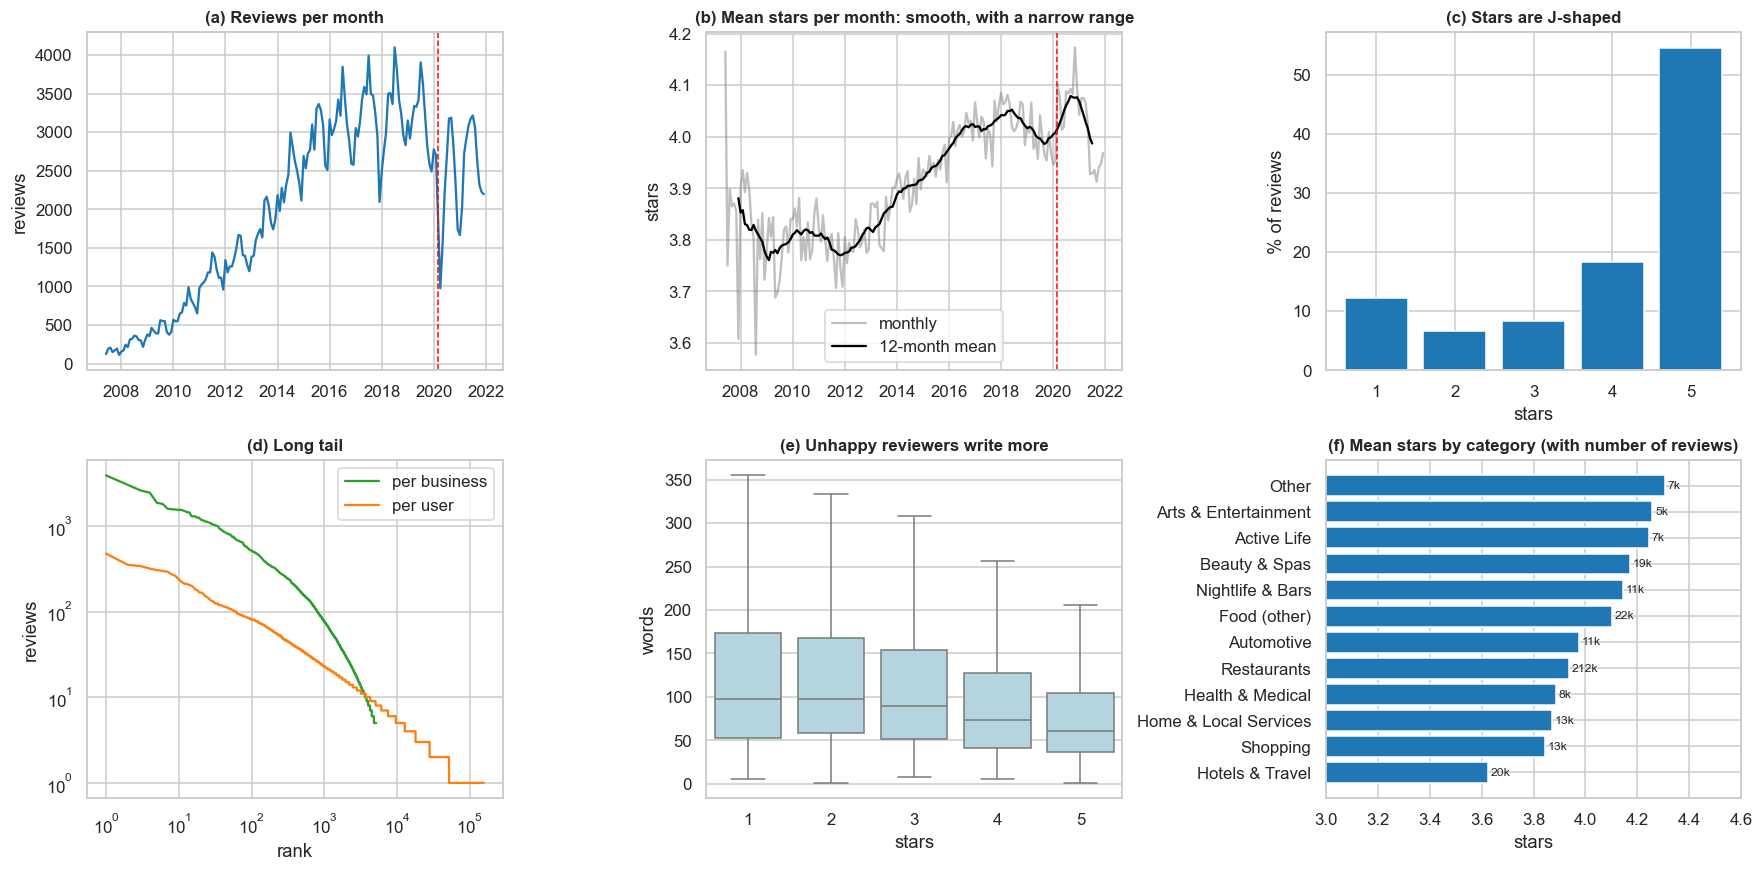

,value
Reviews,"348,014"
Businesses,"5,164"
Users,"155,252"
Mean / median stars,3.96 / 5
Median reviews per business / per user,20 / 1
Users with one review in the subset,66.7%
Businesses with at least 100 reviews,802 (70% of reviews)
Median words per review,71


,share of the variance of stars
between businesses,0.206
between users (users with 5+ reviews),0.264


In [4]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
m = R[R["date"] <= LAST_FULL_MONTH].groupby("month")["stars"].agg(["size", "mean"])
m = m[m.index >= "2007-06-01"]
ax[0, 0].plot(m.index, m["size"], color="tab:blue"); ax[0, 0].set(title="(a) Reviews per month", ylabel="reviews")
ax[0, 0].axvline(COVID_START, color="red", ls="--", lw=1)
ax[0, 1].plot(m.index, m["mean"], color="grey", alpha=.5, label="monthly")
ax[0, 1].plot(m.index, m["mean"].rolling(12, center=True).mean(), color="black", label="12-month mean")
ax[0, 1].axvline(COVID_START, color="red", ls="--", lw=1); ax[0, 1].legend()
ax[0, 1].set(title="(b) Mean stars per month: smooth, with a narrow range", ylabel="stars")
s = R["stars"].value_counts(normalize=True).sort_index() * 100
ax[0, 2].bar(s.index, s.values, color="tab:blue"); ax[0, 2].set(title="(c) Stars are J-shaped", xlabel="stars", ylabel="% of reviews")
for name, col, c in (("per business", "b", "tab:green"), ("per user", "u", "tab:orange")):
    vc = R[col].value_counts().values
    ax[1, 0].loglog(np.arange(1, len(vc) + 1), vc, color=c, label=name)
ax[1, 0].set(title="(d) Long tail", xlabel="rank", ylabel="reviews"); ax[1, 0].legend()
sns.boxplot(data=R.sample(40_000, random_state=SEED), x="stars", y="text_len", showfliers=False, ax=ax[1, 1], color="lightblue")
ax[1, 1].set(title="(e) Unhappy reviewers write more", ylabel="words")
c = R.groupby("macro_cat", observed=True)["stars"].agg(["size", "mean"]).sort_values("mean")
ax[1, 2].barh(c.index, c["mean"], color="tab:blue"); ax[1, 2].set_xlim(3, 4.6)
for i, (n, v) in enumerate(zip(c["size"], c["mean"])):
    ax[1, 2].text(v + .01, i, f"{n / 1000:.0f}k", va="center", fontsize=8)
ax[1, 2].set(title="(f) Mean stars by category (with number of reviews)", xlabel="stars")
savefig("eda_overview")

rb, ru = R["b"].value_counts(), R["u"].value_counts()
display(pd.Series({"Reviews": f"{len(R):,}", "Businesses": f"{len(biz):,}", "Users": f"{n_users:,}",
                   "Mean / median stars": f"{R['stars'].mean():.2f} / {R['stars'].median():.0f}",
                   "Median reviews per business / per user": f"{rb.median():.0f} / {ru.median():.0f}",
                   "Users with one review in the subset": f"{(ru == 1).mean():.1%}",
                   "Businesses with at least 100 reviews": f"{(rb >= 100).sum():,} ({rb[rb >= 100].sum() / len(R):.0%} of reviews)",
                   "Median words per review": f"{R['text_len'].median():.0f}"}, name="value").to_frame())

# variance of the stars: how much belongs to the business, how much to the user?
tot = R["stars"].var()
frequent = R[R["u"].isin(ru[ru >= 5].index)]
display(pd.Series({"between businesses": R.groupby("b")["stars"].transform("mean").var() / tot,
                   "between users (users with 5+ reviews)": frequent.groupby("u")["stars"].transform("mean").var() / frequent["stars"].var()},
                  name="share of the variance of stars").round(3).to_frame())

**What this tells us.** Volume grew until about 2018 and fell sharply with COVID. Mean stars move slowly and in a narrow band, so a single overall stars series has little to forecast: Section 6 therefore forecasts a separate monthly series for each business category. Businesses and users each explain only about a fifth to a quarter of the variance of a single rating, so individual reviews are noisy. Any forecast of a rating will have a limited ceiling, which Section 6 estimates.

## 3. Text processing

**Pipeline.** Normalise the text (case, URLs, whitespace), filter by language, tokenise, and turn the text into features. Instead of assuming which preprocessing steps help, they are **tested**: each variant trains the same classifier on reviews from before 2017 and predicts reviews from 2017-2018.

| Variant | What changes |
|---|---|
| Counts, unigrams | baseline bag of words |
| TF-IDF, unigrams | term weighting |
| TF-IDF, stop-word removal | common words removed, *including "not"* |
| TF-IDF, lemmas (spaCy) | "tasted", "tastes" -> "taste" |
| TF-IDF, bigrams | "not good", "highly recommend" |
| TF-IDF, bigrams and negation tags | "not good" -> `not_good`, so that negation carries over to the next word |

In [5]:
TXT = pd.read_parquet(TEXT_PATH)["text"]
URL = re.compile(r"https?://\S+|www\.\S+")
SPACE = re.compile(r"\s+")
TOKEN = re.compile(r"[a-z']+")
NEG = re.compile(r"\b(not|no|never|without|hardly|isn't|wasn't|aren't|weren't|don't|didn't|doesn't|won't|can't|couldn't|wouldn't|shouldn't)\s+([a-z']+)")
STOP_EN = set("the and a to i was of it for is in that my we they this with you on but have had not at were are so be".split())
STOP_OTHER = set("de la el que y los las un una por para con muy der die und das ist nicht wir ich sehr ein eine le les des et est pour dans une il pas nous per che di il sono".split())


def normalise(t):
    return SPACE.sub(" ", URL.sub(" ", t.lower())).strip()


def mark_negation(t):
    return NEG.sub(lambda m: f"{m.group(1)} not_{m.group(2)}", t)


def looks_english(t):
    """A review is flagged only if words common in Spanish, German, French or Italian outnumber common English words."""
    tok = TOKEN.findall(t.lower())
    other = sum(w in STOP_OTHER for w in tok)
    return not tok or other <= sum(w in STOP_EN for w in tok) or other / len(tok) < .1


R["is_en"] = TXT.map(looks_english).values
print(f"Reviews that do not look English (kept out of the text models): {(~R['is_en']).sum():,} ({(~R['is_en']).mean():.2%})")
for t in TXT[~R["is_en"].values].sample(3, random_state=1):
    print("   ", t[:90].replace("\n", " "))

Reviews that do not look English (kept out of the text models): 355 (0.10%)
    Muchas gracias doctor , David McAninch y personal por su amabilidad y trabajo espectacular
    El ambiente y el servicio es espectacular! Muy lindo lugar. Creo que le erramos en lo que 
    Si vous pouvez aller ailleurs, allez y!!!  Aucun sens du service, accueille froide limite 


In [6]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression, Ridge, SGDClassifier
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, f1_score, mean_absolute_error
from sklearn.model_selection import KFold
from sklearn.preprocessing import normalize

STAR_CLASSES = np.arange(1, 6)


def three_class(s):
    """negative = 1-2 stars, neutral = 3, positive = 4-5"""
    return np.where(np.asarray(s) <= 2.5, 0, np.where(np.asarray(s) < 3.5, 1, 2))


def text_metrics(y, proba_or_expected, classes3=None):
    """Quality of a text model, on the same scale for every method."""
    exp = np.asarray(proba_or_expected)
    return {"macro_F1_3class": f1_score(three_class(y), three_class(exp) if classes3 is None else classes3, average="macro"),
            "accuracy_3class": accuracy_score(three_class(y), three_class(exp) if classes3 is None else classes3),
            "MAE_stars": mean_absolute_error(y, exp), "Spearman": stats.spearmanr(y, exp)[0]}


def sgd():
    return SGDClassifier(loss="log_loss", alpha=2e-6, max_iter=8, tol=None, average=True, random_state=SEED, n_jobs=5)


def lemmatise_sample(ids):
    import spacy
    nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
    texts = [normalise(t)[:3000] for t in TXT.loc[ids]]
    out = [" ".join(w.lemma_ for w in doc if not w.is_punct and not w.is_space) for doc in nlp.pipe(texts, batch_size=256)]
    return pd.DataFrame({"lemma": out}, index=ids)


rng = np.random.default_rng(SEED)
en = R["is_en"].values
tr_ids = rng.choice(np.flatnonzero((R["date"] < TEXT_TRAIN_END).values & en), 30_000, replace=False)
te_ids = rng.choice(np.flatnonzero((R["date"] >= TEXT_TRAIN_END).values & (R["date"] < "2019-01-01").values & en), 10_000, replace=False)
lem = cached("lemmas", lambda: lemmatise_sample(np.r_[tr_ids, te_ids]))["lemma"]
base = dict(min_df=3, max_df=.6, dtype=np.float32)
norm_tr, norm_te = TXT.loc[tr_ids].map(normalise), TXT.loc[te_ids].map(normalise)
y_tr, y_te = R["stars"].values[tr_ids], R["stars"].values[te_ids]

VARIANTS = {
    "Counts, unigrams": (CountVectorizer(binary=True, **base), norm_tr, norm_te),
    "TF-IDF, unigrams": (TfidfVectorizer(sublinear_tf=True, **base), norm_tr, norm_te),
    "TF-IDF + stop-word removal": (TfidfVectorizer(sublinear_tf=True, stop_words="english", **base), norm_tr, norm_te),
    "TF-IDF + lemmas": (TfidfVectorizer(sublinear_tf=True, **base), lem.loc[tr_ids], lem.loc[te_ids]),
    "TF-IDF + bigrams": (TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), **base), norm_tr, norm_te),
    "TF-IDF + bigrams + negation tags": (TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), **base), norm_tr.map(mark_negation), norm_te.map(mark_negation)),
}
rows = []
for name, (vec, a, b) in VARIANTS.items():
    t0 = time.time()
    Xa, Xb = normalize(vec.fit_transform(a)), normalize(vec.transform(b))   # same scale for every variant
    p = sgd().fit(Xa, y_tr).predict_proba(Xb)
    rows.append({"variant": name, **text_metrics(y_te, p @ STAR_CLASSES), "vocabulary": Xa.shape[1], "seconds": time.time() - t0})
RESULTS["text_preprocessing"] = pd.DataFrame(rows).set_index("variant")
display(RESULTS["text_preprocessing"].round(3))
del VARIANTS, norm_tr, norm_te
_ = gc.collect()

,macro_F1_3class,accuracy_3class,MAE_stars,Spearman,vocabulary,seconds
variant,,,,,,
"Counts, unigrams",0.708,0.880,0.430,0.763,17716,3.939
"TF-IDF, unigrams",0.694,0.873,0.448,0.757,17716,3.595
TF-IDF + stop-word removal,0.681,0.866,0.479,0.741,17424,3.814
TF-IDF + lemmas,0.697,0.873,0.455,0.750,13820,3.312
TF-IDF + bigrams,0.728,0.891,0.425,0.780,143867,9.410
TF-IDF + bigrams + negation tags,0.735,0.893,0.419,0.782,145703,10.349


**Reading the table.** Bigrams with negation tags do best (macro-F1 about 0.73, against 0.69 for plain TF-IDF unigrams), and this variant is used in the rest of the notebook. Removing stop words *lowers* quality, because it deletes words such as "not", and lemmas add almost nothing here. Both keep their use elsewhere: they make *topics* readable (Section 4.3), which is a different job from classifying sentiment.

## 4. Sentiment analysis

### 4.1 Which sentiment model? A benchmark on future reviews

Star ratings act as weak labels for the sentiment of a review: 1-2 stars = negative, 3 = neutral, 4-5 = positive. Five approaches are compared on **the same 6,000 reviews written in 2019 or later**:

| Family | Model | Why |
|---|---|---|
| Lexicon | VADER | no training, handles negation and emphasis with rules |
| Supervised | TF-IDF + logistic regression | learns Yelp's own vocabulary from earlier reviews |
| Transfer learning | MiniLM sentence embeddings + logistic regression | pretrained meaning, trained classifier on top |
| Pretrained transformer | DistilBERT (SST-2, movie-review sentences) | off the shelf |
| Pretrained transformer | RoBERTa (Twitter, 3 classes) | off the shelf |

The pretrained models were not built for Yelp or for stars, so each gets a small calibration step (a logistic regression from its output to stars, fitted on 2,000 earlier reviews). All methods then give the same scale: expected stars.

**Coverage.** On this CPU the transformers process 10-70 reviews per second, so they run on samples. VADER and TF-IDF run on all 348k reviews.

**Avoiding a leak.** TF-IDF + LR is trained on reviews before 2017. Reviews from before 2017 get their scores by 5-fold cross-fitting, so no review is scored by a model that saw it. This matters later because these scores become forecast inputs.

In [7]:
def _vader_chunk(texts):
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
    sia = SentimentIntensityAnalyzer()
    return [sia.polarity_scores(t)["compound"] for t in texts]


def compute_vader():
    chunks = np.array_split(TXT.values, N_JOBS * 8)
    res = Parallel(n_jobs=N_JOBS)(delayed(_vader_chunk)(list(c)) for c in chunks)
    return pd.DataFrame({"vader": np.concatenate(res)}, index=TXT.index)


def compute_lr_sentiment():
    """TF-IDF (1-2 grams, negation tags) + logistic regression: expected stars, out of sample for every review."""
    docs = TXT.map(lambda t: mark_negation(normalise(t)))
    train = np.flatnonzero((R["date"] < TEXT_TRAIN_END).values & R["is_en"].values)
    vec = TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), min_df=5, max_df=.5, max_features=400_000, dtype=np.float32)
    vec.fit(docs.iloc[train])
    X = vec.transform(docs)
    del docs; gc.collect()
    y = R["stars"].values
    out = np.full(len(R), np.nan, dtype=np.float32)
    for k, (a, b) in enumerate(KFold(5, shuffle=True, random_state=SEED).split(train)):
        out[train[b]] = sgd().fit(X[train[a]], y[train[a]]).predict_proba(X[train[b]]) @ STAR_CLASSES
    clf = sgd().fit(X[train], y[train])
    rest = np.setdiff1d(np.arange(len(R)), train)
    out[rest] = clf.predict_proba(X[rest]) @ STAR_CLASSES
    names = np.array(vec.get_feature_names_out())
    w = (clf.coef_[4] - clf.coef_[0])                     # 5 stars against 1 star
    top = np.argsort(w)
    terms = pd.DataFrame({"negative": names[top[:25]], "positive": names[top[::-1][:25]]})
    terms.to_parquet(CACHE / "lr_terms.parquet")
    return pd.DataFrame({"sent_lr": out}, index=TXT.index)


R["vader"] = cached("vader", compute_vader)["vader"].values
R["sent_lr"] = cached("lr_sentiment", compute_lr_sentiment)["sent_lr"].values
R["gap"] = R["sent_lr"] - R["stars"]                     # text more positive (+) or negative (-) than the rating
print("Terms that separate 5-star from 1-star reviews most:")
display(pd.read_parquet(CACHE / "lr_terms.parquet").head(15).T)

Terms that separate 5-star from 1-star reviews most:


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
negative,worst,rude,horrible,terrible,one star,awful,not,unprofessional,the worst,disgusting,poor,bad,bland,disappointing,dirty
positive,amazing,great,best,delicious,awesome,excellent,love,perfect,fantastic,wonderful,friendly,the best,favorite,incredible,not_be disappointed


In [8]:
BENCH_IDS = np.random.default_rng(SEED + 1)
pool_old = np.flatnonzero((R["date"] < TEXT_TRAIN_END).values & R["is_en"].values)
pool_new = np.flatnonzero((R["date"] >= "2019-01-01").values & R["is_en"].values)
TEST_IDS = BENCH_IDS.choice(pool_new, 6000, replace=False)
CAL_IDS = BENCH_IDS.choice(pool_old, 2000, replace=False)
EMB_TRAIN_IDS = BENCH_IDS.choice(pool_old, 15_000, replace=False)
TORCH_THREADS = 10


def _batches(texts, tok, bs=32, max_len=128, pairs=None):
    """Sorted by length, which makes the batches smaller and the run faster."""
    order = np.argsort([len(t) for t in texts])
    for s in range(0, len(order), bs):
        idx = order[s:s + bs]
        kw = dict(truncation=True, max_length=max_len, padding=True, return_tensors="pt")
        yield idx, tok([texts[i] for i in idx], [pairs[i] for i in idx], **kw) if pairs is not None else tok([texts[i] for i in idx], **kw)


def transformer_scores(model_name, ids, pairs=None, max_len=128, texts=None):
    """Class probabilities of a classification transformer."""
    import torch
    from transformers import AutoModelForSequenceClassification, AutoTokenizer
    torch.set_num_threads(TORCH_THREADS)
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name).eval()
    texts = [TXT.iloc[i][:1500] for i in ids] if texts is None else texts
    out = None
    with torch.no_grad():
        for idx, enc in _batches(texts, tok, max_len=max_len, pairs=pairs):
            p = torch.softmax(model(**enc).logits, dim=1).numpy()
            if out is None:
                out = np.zeros((len(texts), p.shape[1]), dtype=np.float32)
            out[idx] = p
    del model; gc.collect()
    return pd.DataFrame(out, index=ids, columns=[f"p{k}" for k in range(out.shape[1])])


def minilm_embeddings(ids):
    import torch
    from transformers import AutoModel, AutoTokenizer
    torch.set_num_threads(TORCH_THREADS)
    name = "sentence-transformers/all-MiniLM-L6-v2"
    tok = AutoTokenizer.from_pretrained(name); model = AutoModel.from_pretrained(name).eval()
    texts = [TXT.iloc[i][:1500] for i in ids]
    out = np.zeros((len(ids), 384), dtype=np.float32)
    with torch.no_grad():
        for idx, enc in _batches(texts, tok):
            h = model(**enc).last_hidden_state
            mask = enc["attention_mask"].unsqueeze(-1).float()
            out[idx] = ((h * mask).sum(1) / mask.sum(1)).numpy()
    del model; gc.collect()
    return pd.DataFrame(out, index=ids, columns=[f"e{k}" for k in range(384)])


both = np.r_[CAL_IDS, TEST_IDS]
distil = cached("bench_distilbert", lambda: transformer_scores("distilbert-base-uncased-finetuned-sst-2-english", both))
roberta = cached("bench_roberta", lambda: transformer_scores("cardiffnlp/twitter-roberta-base-sentiment-latest", both))
emb = cached("bench_minilm", lambda: minilm_embeddings(np.r_[EMB_TRAIN_IDS, TEST_IDS]))
print("Transformer scores ready:", distil.shape, roberta.shape, emb.shape)

Transformer scores ready: (8000, 2) (8000, 3) (21000, 384)


,macro_F1_3class,accuracy_3class,MAE_stars,Spearman,F1_low,F1_high,training_reviews,reviews_per_s
model,,,,,,,,
TF-IDF + LR,0.747,0.903,0.424,0.801,0.733,0.763,"171,224","~10,000"
RoBERTa (calibrated),0.668,0.875,0.578,0.711,0.653,0.682,"2,000 (calibration)",~10
DistilBERT (calibrated),0.661,0.866,0.623,0.715,0.647,0.675,"2,000 (calibration)",~20
MiniLM + LR,0.650,0.846,0.558,0.723,0.639,0.662,"15,000",~70
VADER (lexicon),0.588,0.811,0.836,0.527,0.573,0.603,"2,000 (calibration)","~10,000"


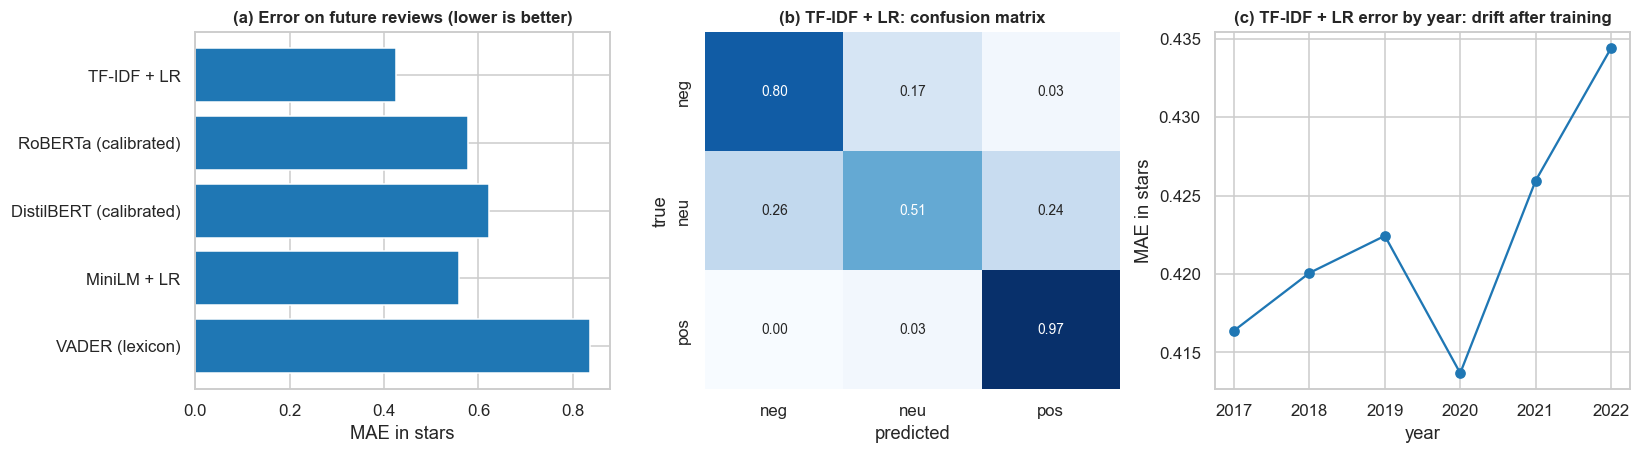

Largest errors of the best model. Some are real contradictions between the text and the stars:


,stars,pred,text
5855,1,4.7,Update: SB Locksmiths got the last laugh on t...
5087,1,4.7,"On the alley is, and was before a Favorite eat..."
679,5,1.3,I ordered take-out here on Cinco De Mayo. They...
2035,1,4.4,I always love coming here. The beauty and cam...
1959,1,4.4,Broke my favorite watch and just sent me away ...
4856,1,4.3,The beer and food are phenomenal. The service ...


In [9]:
def calibrated_stars(Xcal, ycal, Xtest):
    """Logistic regression from a model's raw output to the 5 star classes -> expected stars."""
    clf = LogisticRegression(max_iter=2000, C=10).fit(Xcal, ycal)
    return clf.predict_proba(Xtest) @ clf.classes_


y_true = R["stars"].values[TEST_IDS]
y_cal = R["stars"].values[CAL_IDS]
lg = lambda d, i: np.log(d.loc[i].values + 1e-4)
vad = R["vader"].values
PRED = {
    "VADER (lexicon)": calibrated_stars(np.c_[vad[CAL_IDS], vad[CAL_IDS] ** 3], y_cal, np.c_[vad[TEST_IDS], vad[TEST_IDS] ** 3]),
    "TF-IDF + LR": R["sent_lr"].values[TEST_IDS],
    "MiniLM + LR": LogisticRegression(max_iter=3000, C=3).fit(emb.loc[EMB_TRAIN_IDS].values, R["stars"].values[EMB_TRAIN_IDS]).predict_proba(emb.loc[TEST_IDS].values) @ STAR_CLASSES,
    "DistilBERT (calibrated)": calibrated_stars(lg(distil, CAL_IDS), y_cal, lg(distil, TEST_IDS)),
    "RoBERTa (calibrated)": calibrated_stars(lg(roberta, CAL_IDS), y_cal, lg(roberta, TEST_IDS)),
}
train_size = {"VADER (lexicon)": "2,000 (calibration)", "TF-IDF + LR": f"{int(((R['date'] < TEXT_TRAIN_END) & R['is_en']).sum()):,}", "MiniLM + LR": "15,000",
              "DistilBERT (calibrated)": "2,000 (calibration)", "RoBERTa (calibrated)": "2,000 (calibration)"}
speed = {"VADER (lexicon)": "~10,000", "TF-IDF + LR": "~10,000", "MiniLM + LR": "~70", "DistilBERT (calibrated)": "~20", "RoBERTa (calibrated)": "~10"}
rows = []
for name, p in PRED.items():
    boot = [f1_score(three_class(y_true[i]), three_class(p[i]), average="macro")
            for i in (np.random.default_rng(k).integers(0, len(p), len(p)) for k in range(200))]
    rows.append({"model": name, **text_metrics(y_true, p), "F1_low": np.percentile(boot, 2.5), "F1_high": np.percentile(boot, 97.5),
                 "training_reviews": train_size[name], "reviews_per_s": speed[name]})
RESULTS["sentiment_benchmark"] = pd.DataFrame(rows).set_index("model").sort_values("macro_F1_3class", ascending=False)
display(RESULTS["sentiment_benchmark"].round(3))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
names = RESULTS["sentiment_benchmark"].index
ax[0].barh(names[::-1], RESULTS["sentiment_benchmark"]["MAE_stars"][::-1], color="tab:blue")
ax[0].set(title="(a) Error on future reviews (lower is better)", xlabel="MAE in stars")
best = names[0]
cm = confusion_matrix(three_class(y_true), three_class(PRED[best]), normalize="true")
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", ax=ax[1], xticklabels=["neg", "neu", "pos"], yticklabels=["neg", "neu", "pos"], cbar=False)
ax[1].set(title=f"(b) {best}: confusion matrix", xlabel="predicted", ylabel="true")
d = R[R["is_en"] & (R["date"] >= TEXT_TRAIN_END)].groupby("year").apply(lambda g: mean_absolute_error(g["stars"], g["sent_lr"]))
ax[2].plot(d.index, d.values, "-o", color="tab:blue")
ax[2].set(title="(c) TF-IDF + LR error by year: drift after training", xlabel="year", ylabel="MAE in stars")
savefig("sentiment_benchmark")

errors = pd.DataFrame({"stars": y_true, "pred": PRED[best], "text": [TXT.iloc[i][:170].replace("\n", " ") for i in TEST_IDS]})
errors["err"] = errors["pred"] - errors["stars"]
print("Largest errors of the best model. Some are real contradictions between the text and the stars:")
display(errors.reindex(errors["err"].abs().sort_values(ascending=False).index).head(6)[["stars", "pred", "text"]].round(1))

**Reading the benchmark.** TF-IDF + LR wins clearly (macro-F1 about 0.75; MAE 0.42 stars), ahead of RoBERTa, DistilBERT and MiniLM (0.65-0.67), with VADER last (0.59). **This comparison is not fully even:** TF-IDF + LR learned from about 171,000 Yelp reviews, MiniLM's classifier from 15,000, and the pretrained transformers were not fine-tuned on Yelp at all (fine-tuning needs a GPU). The fair conclusion is that a simple model trained on the domain beats models trained elsewhere, not that TF-IDF is better than transformers in general. All methods find the neutral 3-star class hardest (the best model recalls about half), since 3 stars mix praise and complaints. Error on later years rises only slightly, so the model ages well. The largest errors include real contradictions between text and rating, which motivates the sentiment-star gap (4.6).

### 4.2 Aspect-based sentiment: *what* are people happy or unhappy about?

Overall sentiment says that a review is negative. Aspect-based sentiment says **why**, such as "food fine, service terrible". The steps are:

1. **Discover topics** with NMF on lemmatised text, to see what reviewers talk about, without assuming it (4.3).
2. **Define six aspects** from those topics: food, service, price, ambience, wait, cleanliness.
3. **Score each sentence** that mentions an aspect with VADER, and average per review. VADER is used here because it needs no training on stars, so these features cannot leak ratings into later models.
4. **Check against a transformer**: compare the scores with a dedicated aspect-based model (DeBERTa ABSA) on a sample.

The result is, for each review, a sentiment per aspect that it mentions (missing when it does not mention the aspect).

In [10]:
ASPECT_WORDS = {
    "food": r"food|dish(es)?|menu|meals?|taste[sd]?|tasty|delicious|flavou?rs?|flavou?rful|bland|fresh|pizza|burgers?|sandwich(es)?|tacos?|sushi|breakfast|brunch|lunch|dinner|dessert|appetizers?|salads?|burrito|coffee|wine|beer|cocktails?|drinks?",
    "service": r"service|staff|servers?|waiter|waitress|bartender|hosts?|hostess|manager|owner|employees?|customer service|rude|friendly|helpful|attentive|professional|receptionist",
    "price": r"prices?|pricey|priced|expensive|cheap|overpriced|affordable|worth|value|cost|costs|charged?|fees?|bill|pay|paid|deals?|money",
    "ambience": r"atmosphere|ambian?ce|decor|vibe|music|noisy|loud|patio|cozy|seating|views?|romantic|crowded|outdoor|setting",
    "wait": r"wait|waited|waiting|line|queue|slow|quick|quickly|fast|minutes|mins|hours?|reservations?|on time|late",
    "clean": r"clean|cleaned|cleanliness|dirty|filthy|bathrooms?|restrooms?|smell[sy]?|stinks?|sanitary|tidy|hygiene|gross",
}
ASP_RE = {a: re.compile(rf"\b(?:{p})\b") for a, p in ASPECT_WORDS.items()}
SENT_SPLIT = re.compile(r"(?<=[.!?])\s+|\n+")
COVID_RE = re.compile(r"\b(covid|covid-19|coronavirus|pandemic|quarantine|lockdown|masks?|social distanc\w+)\b")


def _aspect_chunk(texts):
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
    sia = SentimentIntensityAnalyzer()
    out = np.full((len(texts), len(ASPECTS) + 1), np.nan, dtype=np.float32)
    for i, t in enumerate(texts):
        low = t.lower()
        sums = {a: [] for a in ASPECTS}
        for s in SENT_SPLIT.split(low):
            hit = [a for a in ASPECTS if ASP_RE[a].search(s)]
            if hit:
                c = sia.polarity_scores(s)["compound"]
                for a in hit:
                    sums[a].append(c)
        for k, a in enumerate(ASPECTS):
            if sums[a]:
                out[i, k] = np.mean(sums[a])
        out[i, -1] = float(COVID_RE.search(low) is not None)
    return out


def compute_aspects():
    chunks = np.array_split(TXT.values, N_JOBS * 8)
    res = Parallel(n_jobs=N_JOBS)(delayed(_aspect_chunk)(list(c)) for c in chunks)
    return pd.DataFrame(np.vstack(res), index=TXT.index, columns=ASP_COLS + ["covid_mention"])


asp = cached("aspects", compute_aspects)
for c_ in asp.columns:
    R[c_] = asp[c_].values
del asp; gc.collect()
display(pd.DataFrame({"mentioned in % of reviews": R[ASP_COLS].notna().mean() * 100,
                      "mean sentiment": R[ASP_COLS].mean(),
                      "sentiment at 1 star": R.loc[R["stars"] == 1, ASP_COLS].mean(),
                      "sentiment at 5 stars": R.loc[R["stars"] == 5, ASP_COLS].mean()}).round(2))

,mentioned in % of reviews,mean sentiment,sentiment at 1 star,sentiment at 5 stars
asp_food,64.85,0.38,-0.01,0.50
asp_service,53.87,0.42,-0.15,0.60
asp_price,30.25,0.26,-0.03,0.42
asp_ambience,22.34,0.45,0.06,0.55
asp_wait,30.23,0.23,-0.02,0.33
asp_clean,9.59,0.33,-0.15,0.56


**Reading the table.** The four columns:

| Column | Meaning |
|---|---|
| mentioned in % of reviews | share of reviews with at least one sentence about the aspect |
| mean sentiment | average VADER score, counting only the reviews that mention the aspect |
| sentiment at 1 star | the same average, restricted to 1-star reviews |
| sentiment at 5 stars | the same average, restricted to 5-star reviews |

**What it shows**

1. What people talk about. Food is mentioned in 64.9 % of reviews and service in 53.9 %, far ahead of price (30.3 %), wait (30.2 %), ambience (22.3 %) and cleanliness (9.6 %). The percentages add up to more than 100 because one review usually covers several aspects. This fits a dataset dominated by restaurants (212k of the reviews).
2. Overall tone is positive. Every mean is above 0, ranging from 0.23 (wait) to 0.45 (ambience). This matches the J-shaped star distribution: most reviews are 4–5 stars. Wait and price have the lowest means, so they're the aspects people are least enthusiastic about.
3. The 1-star versus 5-star contrast checks that the scores mean something. For every aspect, sentiment is much higher in 5-star than in 1-star reviews, so the scores move with the rating as they should. The size of the gap shows which aspects separate happy from unhappy customers:

| Aspect   | 1 star | 5 stars | Gap  |
|----------|--------|---------|------|
| service  | −0.15  | 0.60    | 0.75 |
| clean    | −0.15  | 0.56    | 0.71 |
| food     | −0.01  | 0.50    | 0.51 |
| ambience | 0.06   | 0.55    | 0.49 |
| price    | −0.03  | 0.42    | 0.45 |
| wait     | −0.02  | 0.33    | 0.35 |

Service and cleanliness have the largest gaps and are the only aspects clearly negative in 1-star reviews. Bad ratings seem to go with complaints about staff and hygiene more than about the food. Food is mentioned in most bad reviews, but its sentences average close to neutral (−0.01).

4. **The 1-star values are mild.** Only service and cleanliness are clearly negative in 1-star reviews (−0.15); food, price, wait and ambience stay near 0. VADER reacts only to emotional words. Complaints about staff and hygiene are usually emotional ("the waitress was rude", "the bathroom was filthy"), and the service and cleanliness dictionaries themselves contain negative words ("rude", "dirty", "filthy", "gross", "stinks"), so these two aspects are partly negative by construction. Complaints about the other aspects are often factual ("we waited 45 minutes", "$30 for a burger"), which VADER scores about 0 even when the customer is unhappy; Section 4.4 confirms this blind spot for wait and price. The scores are therefore best read as relative (higher or lower than in other reviews), not as absolute levels of anger.


### 4.3 Topic check: do the aspects match what reviewers talk about?

NMF is run on the lemmatised sample with stop words removed. If the discovered topics line up with the aspects, then the dictionary reflects real content and not just our assumptions. The table shows the top words of each topic and the aspect dictionary with the largest overlap.

In [11]:
from sklearn.decomposition import NMF

extra_stop = list(ENGLISH_STOP_WORDS | {"just", "get", "go", "got", "good", "great", "like", "place", "really", "come", "time", "would", "say", "try", "know", "make", "take", "come", "want", "look", "'s", "n't", "'m", "'ve", "'re", "'ll"})
tv = TfidfVectorizer(stop_words=extra_stop, min_df=20, max_df=.35, max_features=8000, token_pattern=r"[a-z]{3,}", sublinear_tf=True)
Xl = tv.fit_transform(lem.values)
nmf = NMF(n_components=14, init="nndsvd", random_state=SEED, max_iter=200).fit(Xl)
voc = np.array(tv.get_feature_names_out())
rows = []
for k, comp in enumerate(nmf.components_):
    top = voc[np.argsort(comp)[::-1][:9]]
    hits = {a: sum(bool(ASP_RE[a].fullmatch(w)) for w in top) for a in ASPECTS}
    a_best = max(hits, key=hits.get)
    rows.append({"topic": k, "top words": ", ".join(top), "closest aspect": a_best if hits[a_best] >= 2 else "(business type)", "matching words": hits[a_best]})
RESULTS["nmf_topics"] = pd.DataFrame(rows).set_index("topic")
with pd.option_context("display.max_colwidth", 95):
    display(RESULTS["nmf_topics"])

,top words,closest aspect,matching words
topic,,,
0,"order, chicken, salad, sandwich, eat, burger, fry, fresh, sauce",food,4
1,"work, tell, need, ask, customer, day, car, experience, bad",(business type),0
2,"love, amazing, favorite, absolutely, atmosphere, year, awesome, kid, super",(business type),1
3,"food, service, excellent, restaurant, delicious, atmosphere, customer, mexican, amazing",food,2
4,"room, stay, hotel, clean, beach, nice, location, bed, night",(business type),1
5,"santa, barbara, visit, favorite, stop, restaurant, area, trip, live",(business type),0
6,"wine, tasting, taste, tour, winery, glass, bottle, fun, enjoy",food,2
7,"recommend, highly, amazing, definitely, wedding, professional, work, job, experience",(business type),1
8,"taco, salsa, mexican, fish, chip, burrito, tortilla, asada, bean",food,2


**Reading the topics.** Nine of the 14 topics match an aspect dictionary with at least two of their top words: seven about food and drink (0, 3, 6, 8, 10, 12, 13), one about price (9: price, reasonable, quality, worth, portion) and one about service (11: friendly, staff, helpful, attentive). The other five describe business types or occasions rather than aspects: problems with services and cars (1), enthusiastic praise (2), hotels (4: room, stay, clean, beach), visits to Santa Barbara (5), and weddings and professionals (7). Wait and cleanliness have no topic of their own; they appear inside other topics ("wait" and "hour" in the bar topic 12, "clean" in the hotel and staff topics 4 and 11). So the dictionaries cover what reviewers mostly write about. Wait and cleanliness are the thinnest aspects, which agrees with the weaker scores for wait in Section 4.4.


### 4.4 Check against a dedicated aspect model

No hand-labelled aspect data exist here, so there is no gold standard. Two indirect checks are used on a sample of sentence-aspect pairs: agreement between the VADER scores and the DeBERTa ABSA model, and how well each predicts the stars of the review. A model that reads the aspect in context should do better, and the size of the difference shows what using the fast method costs.

In [12]:
def compute_absa(n_per_aspect=500):
    rng_ = np.random.default_rng(SEED)
    rows = []
    for a in ASPECTS:
        cand = rng_.permutation(np.flatnonzero(R[f"asp_{a}"].notna().values & R["is_en"].values))[:n_per_aspect * 4]
        got = 0
        for i in cand:
            sents = [s for s in SENT_SPLIT.split(TXT.iloc[i]) if ASP_RE[a].search(s.lower()) and 3 <= len(s.split()) <= 60]
            if sents:
                rows.append((int(i), a, sents[0]))
                got += 1
            if got >= n_per_aspect:
                break
    d = pd.DataFrame(rows, columns=["rid", "aspect", "sentence"])
    p = transformer_scores("yangheng/deberta-v3-base-absa-v1.1", d.index.values, pairs=d["aspect"].tolist(),
                           max_len=96, texts=d["sentence"].tolist())
    return pd.concat([d, p], axis=1)


absa = cached("absa_sample", compute_absa)
absa["absa_score"] = absa["p2"] - absa["p0"]             # positive minus negative
absa["absa_class"] = absa[["p0", "p1", "p2"]].values.argmax(1)
vs = pd.Series(np.concatenate(Parallel(n_jobs=N_JOBS)(delayed(_vader_chunk)(list(c)) for c in np.array_split(absa["sentence"].values, N_JOBS))), index=absa.index)
absa["vader_s"] = vs
absa["vader_class"] = np.where(vs <= -.05, 0, np.where(vs >= .05, 2, 1))
absa["stars"] = R["stars"].values[absa["rid"]]
rows = []
for a, g in list(absa.groupby("aspect")) + [("ALL", absa)]:
    rows.append({"aspect": a, "pairs": len(g), "agreement": (g["vader_class"] == g["absa_class"]).mean(), "Cohen kappa": cohen_kappa_score(g["vader_class"], g["absa_class"]),
                 "Spearman(scores)": stats.spearmanr(g["vader_s"], g["absa_score"])[0], "Spearman(VADER, stars)": stats.spearmanr(g["vader_s"], g["stars"])[0],
                 "Spearman(ABSA, stars)": stats.spearmanr(g["absa_score"], g["stars"])[0]})
RESULTS["absa_check"] = pd.DataFrame(rows).set_index("aspect")
display(RESULTS["absa_check"].round(3))

,pairs,agreement,Cohen kappa,Spearman(scores),"Spearman(VADER, stars)","Spearman(ABSA, stars)"
aspect,,,,,,
ambience,500,0.648,0.232,0.503,0.251,0.238
clean,500,0.712,0.411,0.653,0.529,0.546
food,500,0.496,0.205,0.429,0.330,0.282
price,500,0.498,0.219,0.439,0.385,0.525
service,500,0.670,0.326,0.493,0.557,0.514
wait,500,0.308,0.005,0.368,0.290,0.445
ALL,3000,0.555,0.250,0.527,0.414,0.451


**Reading the check.** VADER and the aspect model agree on 56 % of the pairs (kappa 0.25), which is modest. For predicting stars the aspect model is a little better overall (Spearman 0.45 against 0.41). The difference is large for **wait** (kappa near 0, and 0.45 against 0.29) and **price** (0.53 against 0.39): "we waited 40 minutes" contains no emotional words for a lexicon. So the wait and price scores are the weakest parts of this method and should be read with care. The aspect model handled about 26 pairs per second here, so with at least 700,000 review-aspect pairs a full run would take many hours on this CPU, which is why it serves as a check.

### 4.5 What drives the stars, by category?

A regression of a review's stars on its aspect sentiments shows which aspects weigh most in each type of business. Sentiment is standardised, and an unmentioned aspect is set to neutral (0), with an extra indicator for whether it was mentioned. A review's stars and text are written together, so these results describe **what explains a rating** rather than what causes it, and these same-review scores are not used as forecast inputs.

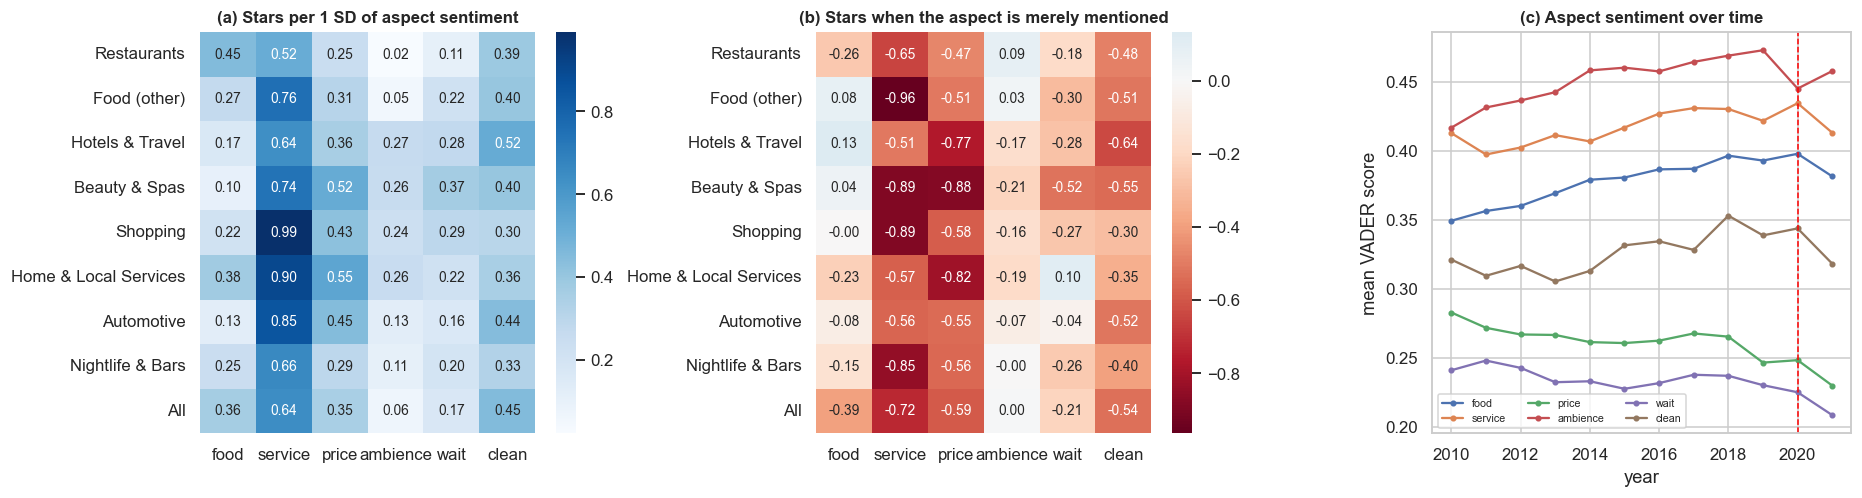

In [13]:
import statsmodels.api as sm


def aspect_drivers(d):
    X = pd.DataFrame(index=d.index)
    for a in ASP_COLS:
        X[a] = (d[a].fillna(0) - d[a].mean()) / d[a].std()
        X["m_" + a] = d[a].notna().astype(float)
    return sm.OLS(d["stars"].values, sm.add_constant(X)).fit(cov_type="HC1")


cats = R["macro_cat"].value_counts().head(8).index.tolist()
rows, mention = {}, {}
for cat in cats + ["All"]:
    d = R[R["is_en"]] if cat == "All" else R[(R["macro_cat"] == cat) & R["is_en"]]
    res = aspect_drivers(d)
    rows[cat] = res.params[ASP_COLS]
    mention[cat] = res.params[["m_" + a for a in ASP_COLS]]
drv = pd.DataFrame(rows).T; drv.columns = ASPECTS
men = pd.DataFrame(mention).T; men.columns = ASPECTS
RESULTS["aspect_drivers"] = drv

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
sns.heatmap(drv, annot=True, fmt=".2f", cmap="Blues", ax=ax[0]); ax[0].set_title("(a) Stars per 1 SD of aspect sentiment")
sns.heatmap(men, annot=True, fmt=".2f", cmap="RdBu", center=0, ax=ax[1]); ax[1].set_title("(b) Stars when the aspect is merely mentioned")
ys = R[R["is_en"] & (R["year"] >= 2010) & (R["date"] <= LAST_FULL_MONTH)].groupby("year")[ASP_COLS].mean()
for a, col in zip(ASPECTS, ASP_COLS):
    ax[2].plot(ys.index, ys[col], "-o", ms=3, label=a)
ax[2].axvline(2020, color="red", ls="--", lw=1); ax[2].legend(ncol=3, fontsize=7)
ax[2].set(title="(c) Aspect sentiment over time", ylabel="mean VADER score", xlabel="year")
savefig("aspect_drivers")

**Reading the figure.**

**(a) Stars per 1 SD of aspect sentiment.** Each cell is a regression coefficient: how many more stars a review gets when its sentiment about that aspect is one standard deviation more positive, with the other five aspects held fixed. Darker blue means a stronger driver.

- Service is the strongest driver in every category, including restaurants (0.52 against 0.45 for food). It's strongest where the experience is mainly an interaction with staff: shopping (0.99), home & local services (0.90) and automotive (0.85).
- Food matters mainly where food is the product: restaurants (0.45) and home & local services (0.38). It matters little in hotels (0.17) or beauty & spas (0.10).
- Price matters most where the bill is large or uncertain: home & local services (0.55), beauty & spas (0.52) and automotive (0.45). It matters least in restaurants (0.25).
- Cleanliness is important everywhere, and most of all in hotels (0.52).
- Ambience barely matters (0.06 overall, 0.02 in restaurants), a little more in hotels and beauty & spas (0.26–0.27).
- Wait is a weak driver (0.17 overall), partly because of VADER's blind spot for factual statements such as "we waited 40 minutes" (Section 4.4), so its true importance is probably understated.

**(b) Stars when the aspect is merely mentioned.** Each cell is the coefficient of the "mentioned" indicator. Unmentioned aspects get a neutral sentiment of 0, so this compares a review that mentions the aspect in neutral terms with one that doesn't mention it at all. Red means fewer stars, blue more.

- Mentioning service, price or cleanliness goes with fewer stars, even in neutral wording: −0.72 for service, −0.59 for price and −0.54 for cleanliness overall. People mostly bring these topics up when something went wrong: satisfied customers rarely write about the bill or the bathroom.
- The extremes support this. In beauty & spas, mentioning price goes with 0.88 fewer stars, and in hotels 0.77 fewer. In food (other), shopping and beauty & spas, mentioning service goes with about 0.9 fewer stars.
- Mentioning ambience is neutral (0.00 overall): it's an ordinary part of describing a place.
- Food is only mildly negative overall (−0.39) and about neutral outside restaurants; it's mentioned in most reviews anyway.

**(c) Aspect sentiment over time** (yearly mean VADER score, English reviews, 2010 onwards; the red line marks 2020).

- The order is stable: ambience is rated most positively (about 0.42–0.47), then service, food and cleanliness. Price and wait are lowest (about 0.21–0.28), consistent with Section 4.2.
- Before 2020, sentiment rose slowly for food, service, ambience and cleanliness, while price and wait stayed flat or slipped slightly.
- Around 2020–2021 most aspects drop: ambience in 2020, then food, service, cleanliness, price and wait by 2021. Service rose briefly in 2020 before falling. Changes during the pandemic (takeout, closed dining rooms, staff shortages) are a possible explanation the notebook doesn't test.

So the tone of what is said about an aspect matters (a), and whether it is mentioned at all already says something (b). These are associations, not causes: stars and text are written together, so the regression describes what goes with a rating, not what produces it.

### 4.6 The sentiment-star gap

`gap = expected stars from the text - actual stars`. A negative gap means that the text is **more negative than the rating**: a polite 4 stars with an unhappy text. If people soften their ratings but not their words, the gap could be an early warning that a business's ratings will fall. This hypothesis is tested with real forecasts in Section 6.3 (ARIMAX + sentiment, whose inputs include the recent change in the gap). Here we only look at how the gap behaves.

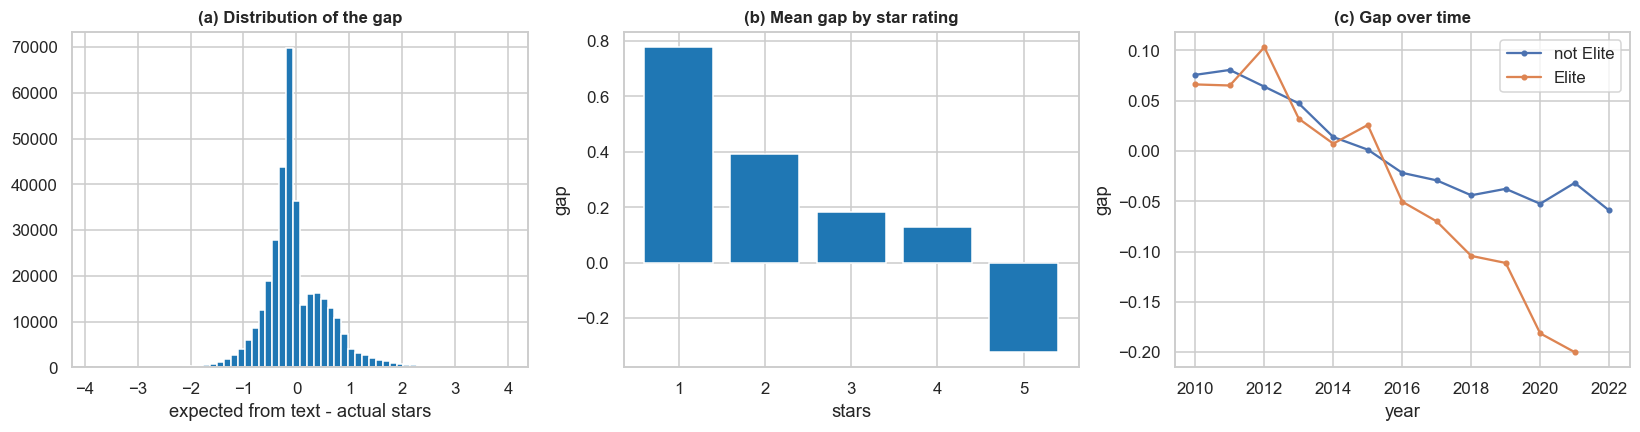

The gap by construction tends to be positive at low stars and negative at high stars, because predictions regress towards the middle. Later analyses therefore compare the gap within a business over time, and control for the stars.


In [14]:
gp = R[R["is_en"]]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(gp["gap"].clip(-4, 4), bins=60, color="tab:blue"); ax[0].set(title="(a) Distribution of the gap", xlabel="expected from text - actual stars")
g = gp.groupby("stars")["gap"].mean(); ax[1].bar(g.index, g.values, color="tab:blue")
ax[1].set(title="(b) Mean gap by star rating", xlabel="stars", ylabel="gap")
g = gp.assign(e=gp["elite_now"]).groupby("e")["gap"].mean()
ybar = gp[gp["year"] >= 2010].groupby(["year", "elite_now"])["gap"].mean().unstack()
ax[2].plot(ybar.index, ybar[False], "-o", ms=3, label="not Elite"); ax[2].plot(ybar.index, ybar[True], "-o", ms=3, label="Elite")
ax[2].legend(); ax[2].set(title="(c) Gap over time", xlabel="year", ylabel="gap")
savefig("sentiment_gap")
print(f"The gap by construction tends to be positive at low stars and negative at high stars, because predictions regress towards the middle. "
      f"Later analyses therefore compare the gap within a business over time, and control for the stars.")

**Reading the figure.**

* **(a) Distribution.** Most gaps lie within ±1 star. The tallest bar is just below 0: 5-star reviews whose text is slightly less glowing than a perfect 5 (the model predicts about 4.7). A second hump at +0.3 to +0.6 comes from lower ratings whose text reads more positive than the stars.
* **(b) By star rating.** The gap falls from +0.78 at 1 star to -0.32 at 5 stars. This is mostly regression to the middle, which every prediction has: the model rarely predicts the extremes. That is why the gap is never compared across star levels, but within a category over time.
* **(c) Over time.** The gap drifts down for everyone, from about +0.07 in 2010 to about -0.05 for non-Elite reviewers by 2020-2021, and much further for Elite reviewers (-0.18 in 2020 and -0.20 in 2021). Either texts became more measured than the stars (Elite reviewers in particular write long, balanced texts while still giving high ratings), or the text model, trained on reviews before 2017, is ageing. The data cannot separate the two. Because the drift is slow and shared by all categories, the forecasting inputs use the gap relative to its own recent level (`gap_dev3`), which removes such slow trends.


## 5. Social network analysis

### 5.1 The friendship network

Users are nodes and friendships are undirected edges, kept only between users in the subset. **Limitations:** this is a single snapshot taken at the end of the data, with no dates, and friends outside the area are missing.

Slow metrics (Louvain communities, approximate betweenness from 100 sampled sources) are stored in the cache.

In [15]:
import networkx as nx
from networkx.algorithms.community import louvain_communities, modularity as nx_modularity
from sklearn.metrics import adjusted_rand_score


def compute_node_metrics():
    G = nx.from_pandas_edgelist(EDGES, "a", "b")
    d = pd.DataFrame(index=pd.Index(sorted(G.nodes), name="u"))
    pr = nx.pagerank(G, alpha=.85, tol=1e-7)
    d["pagerank"] = pd.Series(pr)
    d["core"] = pd.Series(nx.core_number(G))
    comps = max(nx.connected_components(G), key=len)
    H = G.subgraph(comps)
    d["betweenness"] = pd.Series(nx.betweenness_centrality(H, k=100, seed=SEED, normalized=True))
    d["clustering"] = pd.Series(nx.clustering(G, nodes=np.random.default_rng(SEED).choice(list(G.nodes), 20_000, replace=False).tolist()))
    c1 = sorted(louvain_communities(G, seed=SEED), key=len, reverse=True)
    c2 = louvain_communities(G, seed=SEED + 1)
    d["community"] = pd.Series({u: i for i, c in enumerate(c1) for u in c})
    d2 = pd.Series({u: i for i, c in enumerate(c2) for u in c}).reindex(d.index)
    q1, q2 = nx_modularity(G, c1), nx_modularity(G, c2)
    # sampled average shortest path in the largest component
    src = np.random.default_rng(SEED).choice(list(H.nodes), 40, replace=False)
    lens = [np.mean(list(nx.single_source_shortest_path_length(H, int(s)).values())) for s in src]
    # configuration model with the same degrees, for clustering and path length
    deg_seq = [x for _, x in G.degree()]
    C = nx.Graph(nx.configuration_model(deg_seq, seed=SEED)); C.remove_edges_from(nx.selfloop_edges(C))
    nodes_c = np.random.default_rng(SEED).choice(list(C.nodes), 20_000, replace=False).tolist()
    clust_null = nx.average_clustering(C, nodes=nodes_c)
    Hc = C.subgraph(max(nx.connected_components(C), key=len))
    src2 = np.random.default_rng(SEED).choice(list(Hc.nodes), 40, replace=False)
    lens_null = [np.mean(list(nx.single_source_shortest_path_length(Hc, int(s)).values())) for s in src2]
    d.attrs = {}
    meta = pd.DataFrame([{"nodes": G.number_of_nodes(), "edges": G.number_of_edges(), "lcc": len(comps), "components": nx.number_connected_components(G),
                          "n_comm": len(c1), "Q": q1, "Q_seed2": q2, "ARI_seeds": adjusted_rand_score(d["community"], d2),
                          "path": float(np.mean(lens)), "path_null": float(np.mean(lens_null)), "clust_null": clust_null}])
    meta.to_parquet(CACHE / "net_meta.parquet")
    del G, H, C, Hc; gc.collect()
    return d.reset_index()


NODES = cached("node_metrics", compute_node_metrics).set_index("u")
meta = pd.read_parquet(CACHE / "net_meta.parquet").iloc[0]
NODES["degree"] = deg[NODES.index]
netdeg = NODES["degree"]
display(pd.Series({"Nodes (users with a friend in the subset)": f"{int(meta['nodes']):,} of {n_users:,}", "Edges": f"{int(meta['edges']):,}",
                   "Density": f"{2 * meta['edges'] / (meta['nodes'] * (meta['nodes'] - 1)):.6f}",
                   "Mean / median / max degree": f"{netdeg.mean():.1f} / {netdeg.median():.0f} / {netdeg.max():,}",
                   "Components; largest": f"{int(meta['components']):,}; {meta['lcc'] / meta['nodes']:.1%} of the nodes",
                   "Average clustering (observed vs same degrees, random)": f"{NODES['clustering'].mean():.3f} vs {meta['clust_null']:.3f}",
                   "Mean path length (observed vs same degrees, random)": f"{meta['path']:.2f} vs {meta['path_null']:.2f}",
                   "Louvain communities; modularity Q": f"{int(meta['n_comm']):,}; {meta['Q']:.3f}",
                   "Stability: Q with another seed; adjusted Rand index": f"{meta['Q_seed2']:.3f}; {meta['ARI_seeds']:.2f}"}, name="value").to_frame())

,value
Nodes (users with a friend in the subset),"64,154 of 155,252"
Edges,"471,089"
Density,0.000229
Mean / median / max degree,"14.7 / 4 / 2,007"
Components; largest,"1,093; 96.3% of the nodes"
"Average clustering (observed vs same degrees, random)",0.098 vs 0.020
"Mean path length (observed vs same degrees, random)",4.26 vs 3.72
Louvain communities; modularity Q,"1,676; 0.526"
Stability: Q with another seed; adjusted Rand index,0.518; 0.57


### 5.2 Who befriends whom? Homophily and the opinion network

If friends rate alike, it matters for all that follows. The **assortativity** of an attribute is its correlation across the two ends of a friendship. To tell whether a value is large, it is compared with a null model in which the attribute is shuffled among the nodes. These user attributes describe all of a user's reviews, so this analysis describes the network and is not used for forecasting.

How it's measured

Assortativity. For every friendship edge, the code takes the attribute value of both users. It computes the Pearson correlation between the values at the two ends, counting each edge in both directions so the order doesn't matter.
- +1 means friends always have the same value.
- 0 means no relation between friends' values.
- Negative means opposites connect.

Null model. To judge whether a value is large, the attribute values are shuffled randomly among the users, keeping the network fixed. Assortativity is then recomputed, 100 times. This shows what you'd see if friendships ignored the attribute entirely.

z vs null = (observed − null mean) / null SD. It counts how many standard deviations the real value lies above chance.

Filter for opinions. For the opinion attributes (stars, sentiment), only users with at least 3 reviews are kept, because an average over 1–2 reviews is too noisy. That's why those rows use fewer edges (about 100k instead of 471k). The aspect rows need users who also mention the aspect, so they have even fewer.

In [16]:
ua = R.groupby("u").agg(n=("stars", "size"), stars=("stars", "mean"), sent=("sent_lr", "mean"), vader=("vader", "mean"), gap=("gap", "mean"),
                        elite=("elite_now", "max"), first_year=("year", "min"), text_len=("text_len", "mean"))
ua = ua.reindex(np.arange(n_users))
ua["join_year"] = USERS.set_index("u")["join_year"].reindex(np.arange(n_users)).values
ua["log_reviews"] = np.log1p(ua["n"])
ua["log_degree"] = np.log1p(deg)
for a in ASP_COLS:
    ua[a] = R.groupby("u")[a].mean().reindex(np.arange(n_users)).values


def assortativity(x, mask=None, n_perm=100):
    a, b = EDGES["a"].values, EDGES["b"].values
    x = np.asarray(x, float)
    keep = np.isfinite(x)
    if mask is not None:
        keep &= mask
    ok = keep[a] & keep[b]
    a, b = a[ok], b[ok]
    corr = lambda v: np.corrcoef(np.r_[v[a], v[b]], np.r_[v[b], v[a]])[0, 1]
    obs = corr(x)
    ids = np.unique(np.r_[a, b])
    rng_ = np.random.default_rng(SEED)
    null = []
    for _ in range(n_perm):
        y = x.copy(); y[ids] = rng_.permutation(x[ids])
        null.append(corr(y))
    return obs, np.mean(null), np.std(null), len(a)


multi = (ua["n"] >= 3).values                            # opinions of users with very few reviews are too noisy
rows = []
for name, col, mask in (("log degree", "log_degree", None), ("log number of reviews", "log_reviews", None), ("join year", "join_year", None), ("Elite ever", "elite", None),
                        ("mean stars given (3+ reviews)", "stars", multi), ("mean text sentiment (3+ reviews)", "sent", multi),
                        ("service sentiment (3+ reviews)", "asp_service", multi), ("food sentiment (3+ reviews)", "asp_food", multi)):
    o, m_, s_, n_ = assortativity(ua[col].astype(float), mask)
    rows.append({"attribute": name, "assortativity": o, "null mean": m_, "z vs null": (o - m_) / s_, "edges": n_})
RESULTS["assortativity"] = pd.DataFrame(rows).set_index("attribute")
display(RESULTS["assortativity"].round(3))

,assortativity,null mean,z vs null,edges
attribute,,,,
log degree,0.298,-0.000,195.645,471089
log number of reviews,0.166,-0.000,127.131,471089
join year,0.495,0.000,350.998,471089
Elite ever,0.452,-0.000,295.430,471089
mean stars given (3+ reviews),0.053,-0.001,17.737,100164
mean text sentiment (3+ reviews),0.055,-0.001,19.170,100164
service sentiment (3+ reviews),0.008,-0.001,2.340,88173
food sentiment (3+ reviews),0.045,-0.001,13.722,94828


**Reading the table.** Friendship is sorted mainly by **activity**, much less by **opinion**.

* **Activity: strong homophily.** Join year (0.50): people join in waves and add friends who joined with them. Elite (0.45): Elite users meet at Elite events and form their own circle. Degree (0.30) and number of reviews (0.17): heavy users connect with heavy users, as in most social networks.
* **Opinions: weak homophily.** Mean stars (0.05) and mean sentiment (0.06) are barely correlated between friends: a correlation of 0.05 explains about 0.3 % of the variation (0.05² ≈ 0.0025). Service sentiment (0.008) shows essentially none.
* **Significant is not large.** Every z-value is above 2, but with 88k–471k edges the null model's SD is tiny, so even a negligible correlation is significant. The z-score says that an effect is not zero; the assortativity says how large it is. Service sentiment (z = 2.3) is barely distinguishable from zero, given that eight attributes were tested.

So a friendship tie carries little general information about opinions, and the later analyses do not expect a friend's rating to predict a user's rating strongly. Two caveats: the user attributes summarise all of a user's reviews, including those written after a friendship formed, so choosing similar friends (selection) cannot be separated from becoming similar to them (influence); and only users in the subset are included.

### 5.3 Communities and central users: what knowledge does the network give?

The top communities are described by size, activity and opinions. For categories, **lift** shows what a community reviews more than average: 1.5 means 50 % more than expected. A separate table shows that the various centrality measures partly capture the same thing, and how they relate to activity.

Communities with at least 5,000 reviews: 6; they hold 52% of all reviews


,users,reviews,median degree,mean join year,reviews by Elite %,share in Santa Barbara %,reviews per user,mean stars,mean sentiment,top category (lift)
community,,,,,,,,,,
0,17263,59445,6,2013.1,4.56,77.25,3.44,4.04,4.02,Health & Medical (1.64)
4,7119,41500,3,2012.5,32.22,73.82,5.83,4.04,4.00,Food (other) (1.22)
1,10771,27294,6,2010.9,45.29,82.70,2.53,4.01,3.98,Arts & Entertainment (1.74)
2,9188,24402,3,2010.4,40.30,82.74,2.66,4.00,3.98,Hotels & Travel (1.40)
5,5962,15358,6,2014.3,17.86,58.21,2.58,3.94,3.90,Nightlife & Bars (1.25)
3,7822,13160,3,2011.8,5.30,81.21,1.68,4.07,4.04,Hotels & Travel (1.60)


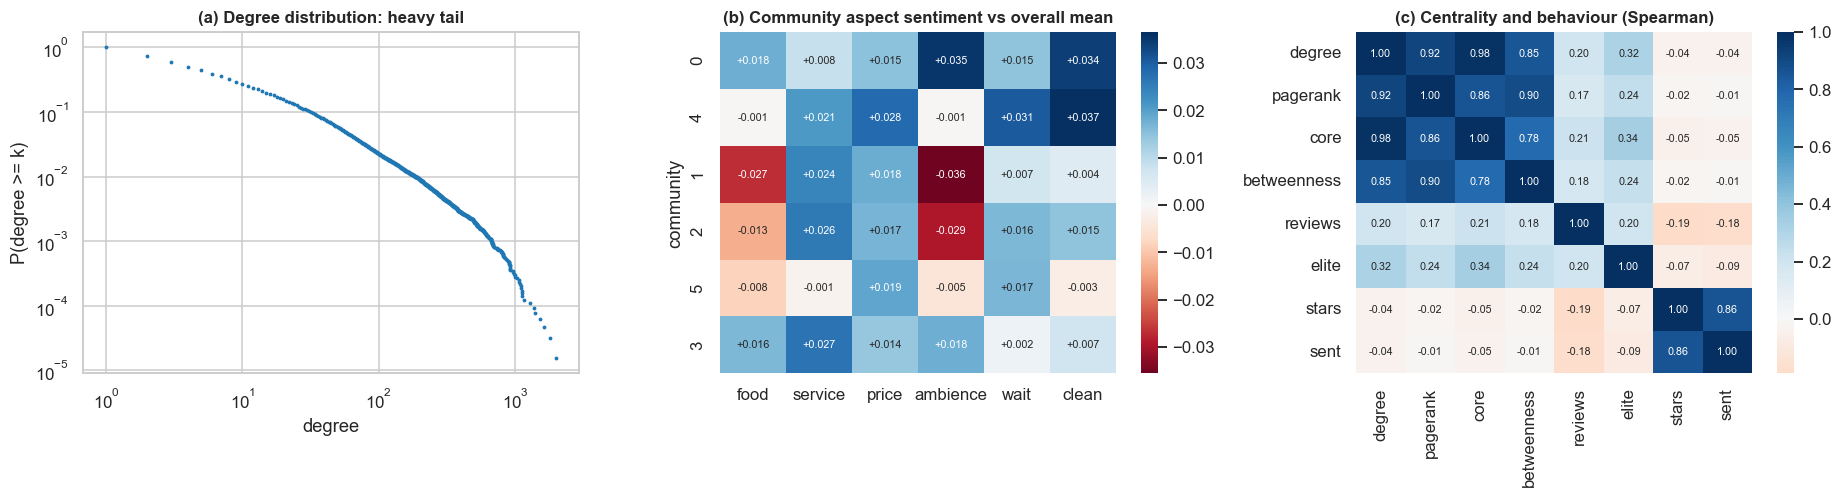

In [17]:
R["community"] = R["u"].map(NODES["community"])
vc_comm = R["community"].value_counts()
top_comm = vc_comm[vc_comm >= 5000].index.astype(int).tolist()   # the communities large enough to describe
print(f"Communities with at least 5,000 reviews: {len(top_comm)}; they hold {vc_comm[vc_comm >= 5000].sum() / len(R):.0%} of all reviews")
overall_cat = R["macro_cat"].value_counts(normalize=True)
overall_city = (R["city"] == "Santa Barbara").mean()
rows = []
for c in top_comm:
    g = R[R["community"] == c]
    members = NODES.index[NODES["community"] == c]
    lift = (g["macro_cat"].value_counts(normalize=True) / overall_cat).dropna()
    shares = g["macro_cat"].value_counts(normalize=True)
    lift = lift[shares.reindex(lift.index) >= .02].sort_values(ascending=False)
    rows.append({"community": c, "users": len(members), "reviews": len(g), "median degree": int(NODES.loc[members, "degree"].median()),
                 "mean join year": round(USERS.set_index("u").loc[members, "join_year"].mean(), 1), "reviews by Elite %": 100 * g["elite_now"].mean(),
                 "share in Santa Barbara %": 100 * (g["city"] == "Santa Barbara").mean(), "reviews per user": len(g) / len(members),
                 "mean stars": g["stars"].mean(), "mean sentiment": g["sent_lr"].mean(), "top category (lift)": f"{lift.index[0]} ({lift.iloc[0]:.2f})"})
RESULTS["community_profile"] = pd.DataFrame(rows).set_index("community")
display(RESULTS["community_profile"].round(2))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
vals, cnt = np.unique(netdeg, return_counts=True)
ccdf = 1 - np.cumsum(cnt) / cnt.sum() + cnt / cnt.sum()
ax[0].loglog(vals, ccdf, ".", ms=3, color="tab:blue"); ax[0].set(title="(a) Degree distribution: heavy tail", xlabel="degree", ylabel="P(degree >= k)")
asp_dev = pd.DataFrame({c: R.loc[R["community"] == c, ASP_COLS].mean() - R[ASP_COLS].mean() for c in top_comm}).T
asp_dev.columns = ASPECTS
sns.heatmap(asp_dev, annot=True, fmt="+.3f", cmap="RdBu", center=0, ax=ax[1], annot_kws={"size": 7}); ax[1].set_title("(b) Community aspect sentiment vs overall mean")
ax[1].set_ylabel("community")
centr = NODES[["degree", "pagerank", "core", "betweenness"]].join(ua[["n", "elite", "stars", "sent"]]).rename(columns={"n": "reviews"}).dropna(subset=["betweenness"]).astype(float)
sp_corr = centr.corr(method="spearman")
sns.heatmap(sp_corr, annot=True, fmt=".2f", cmap="RdBu", center=0, ax=ax[2], annot_kws={"size": 7}); ax[2].set_title("(c) Centrality and behaviour (Spearman)")
savefig("network_structure")
RESULTS["centrality_spearman"] = sp_corr

**Reading the tables and the figure.**

**Network structure (table in 5.1).** It is a small world: clustering is about 5 times that of a random network with the same degrees (0.098 against 0.020), with a similar path length (4.3 against 3.7 steps). Louvain finds clear structure (Q = 0.53), but the exact boundaries depend on the seed (adjusted Rand index 0.57 between two runs), so communities are useful groupings, not exact facts.

**Communities (table above).** Six communities hold 52 % of all reviews and differ in character. C1 and C2 are older, Elite-heavy groups (mean join year about 2010-2011; 40-45 % of their reviews by Elite users). C0 is the largest and has few Elite reviews (5 %). C4 has the most reviews per user (5.8). C3 has the fewest (1.7) and leans to hotels and travel, which suggests visitors, and C5 has the lowest share of reviews in Santa Barbara itself (58 %). Mean stars differ little (3.94-4.07).

**(a) Degree distribution, a heavy tail.** A user's degree is their number of friends within the subset. The plot shows, for each degree k, the share of users with at least k friends, P(degree ≥ k), on logarithmic axes.
- The curve starts at 1 because every user in the network has at least one friend.
- About 27 % of users have at least 10 friends, and the curve passes 10⁻¹ near 30 friends (11 % of users).
- It passes 10⁻² near 150 friends: about 2 % of users have 100 or more friends and 1.3 % have 150 or more.
- It extends to about 2,000 friends, where only a handful of users remain (about 10⁻⁵); only 0.03 % have 1,000 or more.

The curve falls slowly and nearly straight across three orders of magnitude, the typical shape of a heavy-tailed network: most users have a few friends, a few hubs have hundreds or thousands. The bend at the end shows that the tail is heavy but not unlimited (no formal power-law test is made). Any spreading of opinions through the network would run mainly through the hubs.

**(b) Community aspect sentiment against the overall mean.** Each cell shows how far a community's average VADER sentiment for an aspect is from the overall average (blue = more positive, red = more negative; C0 is the largest community).
- The differences are tiny: between −0.036 and +0.037 on a scale from −1 to +1, while the overall means are about 0.23–0.45 (Section 4.2).
- There are faint patterns. C0 is slightly more positive about ambience and cleanliness (+0.035 and +0.034), and C4 about cleanliness, wait and price (+0.037, +0.031, +0.028). The older, Elite-heavy C1 and C2 are slightly more negative about food and ambience (down to −0.036) but slightly more positive about service, which fits panel (c), where active reviewers give lower stars.

**(c) Centrality and behaviour (Spearman correlations per user).**
1. The centrality measures largely say the same thing. Degree correlates 0.98 with core, 0.92 with PageRank and 0.85 with betweenness, and all pairs are at 0.78 or above. Degree alone captures most of it.
2. Network position is only weakly related to activity: 0.17–0.21 with the number of reviews, and 0.24–0.34 with Elite status. Many hubs are social users who review little here, perhaps because they review mainly in other cities.
3. Centrality says nothing about opinions: the correlations with stars and sentiment are about −0.01 to −0.05.
4. Heavy reviewers rate a bit lower: reviews correlate −0.19 with stars and −0.18 with sentiment. Stars and sentiment correlate 0.86, which mainly confirms that the sentiment model tracks ratings.

**In short,** the network has clear structure (a heavy tail, a small world, distinct communities), but that structure is about social activity, not opinions: communities differ in who they are (age, Elite share, categories, residents against visitors) much more than in what they think, and central users don't rate differently. This matches 5.2. Betweenness is a sampled estimate.

### 5.4 Influence: do friends rate alike?

Yelp has no record of who read what, so influence has to be inferred. The main threats are **homophily** (friends have similar tastes) and **joint visits** (friends go together). The test below is designed around these threats.

**Rating conformity, friend against matched stranger.** A rating's *deviation* is its stars minus the mean of all earlier reviews of the same business. Take a review by user *v* at business *b*, preceded by a review from a friend of *v*. Pair it with an earlier review of *b* by a **non-friend written as close as possible in time to the friend's**, which holds the business and period nearly fixed. Then regress *v*'s rating deviation on both reviewers' deviations, controlling for how generous each person usually is (their earlier deviations elsewhere), with business and quarter fixed effects. The clues are:

* friend > non-friend: rating is more similar among friends;
* a *friend of a friend* (no direct tie) against a stranger: a large effect here would suggest shared tastes more than direct influence;
* decay with the time since the friend's review: influence should fade, while stable shared tastes should not.

Same-day reviews are reported separately because they likely reflect joint visits.

In [18]:
R = R.sort_values(["date"], kind="stable")
R["prior_mean"] = R.groupby("b")["stars"].transform(lambda s: s.shift().expanding().mean())
R["prior_n"] = R.groupby("b").cumcount()
R["dev"] = R["stars"] - R["prior_mean"]
R["lenient"] = R.groupby("u")["dev"].transform(lambda s: s.shift().expanding().mean()).fillna(0)
R["rid"] = R.index
ptr, ind = A.indptr, A.indices


def compute_pairs():
    """For every review with an earlier friend review of the same business: most recent friend + matched non-friend."""
    D = R[["b", "u", "stars", "day", "prior_mean", "prior_n", "lenient", "q", "rid"]].sort_values(["b", "day"], kind="stable")
    bb, uu, ss, dd, pm, pn, ln, ridd = [D[c].values for c in ("b", "u", "stars", "day", "prior_mean", "prior_n", "lenient", "rid")]
    cut = np.r_[0, np.flatnonzero(np.diff(bb)) + 1, len(bb)]
    rows = []
    for s, e in zip(cut[:-1], cut[1:]):
        if e - s < 6:
            continue
        pos = {}                                         # user -> last position in this business
        for i in range(s, e):
            v = uu[i]
            nb = ind[ptr[v]:ptr[v + 1]]
            if len(nb) and pos and pn[i] >= 5:
                fset = set(nb.tolist())
                friends = [pos[f] for f in fset if f in pos] if len(fset) <= len(pos) else [p for w, p in pos.items() if w in fset]
                if friends:
                    f = max(friends)
                    # nearest earlier non-friend reviewer, searching outwards from the friend's position
                    n_ = -1
                    for off in range(1, e - s):
                        for j in (f - off, f + off):
                            if s <= j < i and uu[j] != v and uu[j] not in fset:
                                n_ = j
                                break
                        if n_ >= 0:
                            break
                    if n_ >= 0:
                        common = np.intersect1d(nb, ind[ptr[uu[n_]]:ptr[uu[n_] + 1]], assume_unique=True).size
                        rows.append((ridd[i], bb[i], v, ss[i], pm[i], ln[i], ss[f], ln[f], dd[i] - dd[f], ss[n_], ln[n_], abs(dd[f] - dd[n_]), common, len(friends)))
            pos[v] = i
    return pd.DataFrame(rows, columns=["rid", "b", "u", "y", "pm", "len_v", "s_f", "len_f", "lag", "s_n", "len_n", "match_days", "n_common", "n_friends"])


P = cached("influence_pairs", compute_pairs)
P["y_dev"] = P["y"] - P["pm"]; P["x_f"] = P["s_f"] - P["pm"]; P["x_n"] = P["s_n"] - P["pm"]
P["q"] = R.loc[P["rid"].values, "q"].astype(str).values
P["fof"] = (P["n_common"] > 0).astype(float)


def conformity(d, extra=()):
    cols = ["y_dev", "x_f", "x_n", "len_v", "len_f", "len_n", *extra]
    W = within(d, cols, ["b", "q"])
    return ols_cluster(W["y_dev"], W[cols[1:]], d["u"].values)


rows = []
for label, mask in (("all lags (1+ days)", P["lag"] >= 1), ("same day (joint visits?)", P["lag"] == 0), ("1-30 days", P["lag"].between(1, 30)),
                    ("31-180 days", P["lag"].between(31, 180)), ("181-730 days", P["lag"].between(181, 730)), ("over 2 years", P["lag"] > 730)):
    d = P[mask]
    m = conformity(d)
    t = m.t_test("x_f - x_n = 0")
    rows.append({"time since friend's review": label, "pairs": len(d), "friend": m.params["x_f"], "friend_se": m.bse["x_f"], "non-friend": m.params["x_n"], "non-friend_se": m.bse["x_n"],
                 "difference": float(t.effect[0]), "diff_se": float(t.sd[0][0]), "p": float(t.pvalue)})
RESULTS["conformity_by_lag"] = pd.DataFrame(rows).set_index("time since friend's review")
display(RESULTS["conformity_by_lag"].round(4))

# friend of a friend vs total stranger: is the non-friend socially close?
d = P[P["lag"] >= 1].copy()
d["x_n_fof"] = d["x_n"] * d["fof"]
m = conformity(d, extra=("x_n_fof", "fof"))
print(f"Non-friend reviewer who IS a friend of a friend: extra effect {m.params['x_n_fof']:+.4f} (SE {m.bse['x_n_fof']:.4f}, p = {m.pvalues['x_n_fof']:.3f}); "
      f"share of pairs {d['fof'].mean():.1%}; stranger effect {m.params['x_n']:+.4f} (SE {m.bse['x_n']:.4f})")
RESULTS["conformity_fof"] = pd.DataFrame({"coef": m.params, "se": m.bse, "p": m.pvalues}).loc[["x_f", "x_n", "x_n_fof"]]

,pairs,friend,friend_se,non-friend,non-friend_se,difference,diff_se,p
time since friend's review,,,,,,,,
all lags (1+ days),30937,0.1270,0.0084,0.0098,0.0056,0.1172,0.0098,0.0000
same day (joint visits?),933,0.9042,0.0229,0.0019,0.0204,0.9024,0.0293,0.0000
1-30 days,4187,0.3737,0.0231,0.0440,0.0133,0.3297,0.0268,0.0000
31-180 days,7726,0.1089,0.0155,0.0048,0.0109,0.1040,0.0191,0.0000
181-730 days,11257,0.0544,0.0121,0.0108,0.0092,0.0436,0.0151,0.0039
over 2 years,7767,0.0810,0.0153,0.0017,0.0124,0.0793,0.0202,0.0001


Non-friend reviewer who IS a friend of a friend: extra effect +0.0105 (SE 0.0154, p = 0.496); share of pairs 19.6%; stranger effect +0.0087 (SE 0.0060)


**Reading the results.** A coefficient is the change in *v*'s deviation per star of the other reviewer's deviation: 0.127 means that when the friend rated 1 star above the business's earlier average, *v* rated about 0.13 stars above it.

* **Friend against stranger.** A friend's earlier rating is far more informative than a matched stranger's: 0.127 against 0.010 for all lags of 1+ days (difference p < 0.001). The stranger's coefficient is close to 0 at every lag.
* **Same day.** Same-day reviews reach 0.90, almost identical ratings. They most likely reflect joint visits, so they are not counted as influence.
* **Decay.** The effect is 0.37 within 30 days, 0.11 at 1-6 months and about 0.05-0.08 after that. Influence should fade as the friend's review is forgotten, whereas shared taste should not depend on timing, so the small remainder after years is probably shared taste.
* **Friend of a friend.** In 19.6 % of pairs the "stranger" is a friend of a friend. Their extra effect is +0.011 (p = 0.50), so they are no more similar than a complete stranger. The similarity is tied to a direct tie, not to a broad circle of like-minded people.
* **Common shocks.** The small stranger effect at 1-30 days (0.044) reflects what affects everyone at the same time, such as a business having a good or bad month.

**What can be claimed.** The decay and the failed friend-of-friend link favour something specific to friends over general homophily. But reviews within 30 days can still be joint visits written up on different days, and the friendship list is an undated snapshot, so the evidence is compatible with influence without proving it. Section 7 builds on these results twice: to estimate how large a network effect on a category's monthly mean could be (7.1), and to forecast individual ratings (7.2).

## 6. Time series: forecasting the stars of each business category

Businesses are grouped into the **12 categories of Section 2** (Restaurants, Nightlife & Bars, Food (other), Beauty & Spas, and so on), and the forecast target is the **mean stars of a category in the next month**. A single business gets too few reviews for a reliable monthly mean, but a category gets enough: since 2012 every category has at least 15 reviews in every month, and Restaurants about 1,500.

* **6.1 The category series** - data, test design, inputs and simple baselines.
* **6.2 Diagnostics** - trend, season, stationarity, noise and autocorrelation of each category's series.
* **6.3 Local ARIMA-type models** - one classical model per category, fitted only on its own series.
* **6.4 Global models** - one LightGBM (or Ridge) model trained on all categories together, with the history, sentiment and network inputs.

All models are evaluated on the same category-months (targets January 2018 to December 2021) with the same walk-forward design, so their errors are directly comparable.

### 6.1 The category series: data, test design and baselines

**Series.** For each of the 12 categories, the mean stars of all its reviews in each month, from January 2010 (inputs) and January 2012 (series used by the models) to December 2021. Every category-month counts equally in the errors, so that small categories matter as much as Restaurants.

**Test design (walk-forward).** For each target month from January 2018 to December 2021, every model is refitted on the data known at the forecast origin and forecasts the next month. 2014-2017 (48 months, predicted the same way) serves for choosing hyperparameters. Results are split into before COVID (2018-2019) and COVID (2020-2021).

**Baselines:**

| Baseline | Forecast for the next month | What it tests |
|---|---|---|
| **Last month** | the category's mean stars this month | is the latest month enough? |
| **Mean of the last 12 months** | the review-weighted mean of the last year | the **reference**: the global models predict the difference from it, and "skill" is measured against it |
| **Long-run mean** | the mean of all reviews since 2010 | does the series return to a fixed level? |
| **Seasonal naive** | the same month one year earlier | is there a usable yearly pattern? |

**Noise limit.** A mean of *n* reviews has sampling noise even when the true level is known. The **noise floor** is the error that a model knowing each category's true monthly level could not avoid.

**Three groups of inputs**, all from reviews written up to the forecast origin:

| Group | Inputs |
|---|---|
| **History** | stars this month and the two before, means over 3 and 12 months and since 2010, the 3-versus-12-month trend, the same month a year earlier, volume, spread of stars, overall market level, month of the year, category |
| **Sentiment** | mean sentiment, sentiment-star gap and VADER score this month, over 3 and 12 months, and the 3-month change; aspect sentiment (food, service, price, ambience, wait, clean) over 3 months and its change |
| **Network** | how connected recent reviewers are, the share of reviews by someone with a friend who reviewed the same business earlier and those reviews' deviation, PageRank-weighted stars, the recent mood of the reviewers' friends, and how generous those friends usually are |

Each group enters the global models **as a whole** (17 history, 30 sentiment and 7 network inputs), so that a group is judged by everything it contains rather than by a few inputs picked with hindsight. Overfitting is kept in check by the models themselves (shallow trees, a Ridge penalty), with settings chosen on 2014-2017.

The same network inputs are also computed on a **scrambled (placebo) friendship graph**, for the tests in Section 7.

In [19]:
CATS = sorted(R["macro_cat"].unique())
PM = pd.period_range("2010-01", "2021-12", freq="M")
mi = {p: i for i, p in enumerate(PM)}
ci_of = {c: i for i, c in enumerate(CATS)}
nC, nM = len(CATS), len(PM)
in_window = (R["date"] >= PM[0].start_time) & (R["date"] < PM[-1].end_time)
Rc = R[in_window].copy()
Rc["ci"] = Rc["macro_cat"].map(ci_of).astype(int)
Rc["mi"] = Rc["month"].dt.to_period("M").map(mi).astype(int)
TS0 = mi[pd.Period("2012-01", "M")]                       # start of the series used by the models
print(f"{nC} categories, {nM} months, {len(Rc):,} reviews")


def cgrid(df, col=None):
    """nC x nM matrix with the sum of a column (or a count) per category and month."""
    M = np.zeros((nC, nM))
    v = np.ones(len(df)) if col is None else df[col].fillna(0).values.astype(float)
    np.add.at(M, (df["ci"].values, df["mi"].values), v)
    return M


def roll(M, k):
    """Sum over the last k months, including the current one."""
    c = np.cumsum(M, axis=1)
    out = c.copy()
    out[:, k:] = c[:, k:] - c[:, :-k]
    return out


def safe(a, b):
    return np.where(b > 0, a / np.where(b > 0, b, 1), np.nan)


def lag(M, k):
    out = np.full_like(M, np.nan)
    out[:, k:] = M[:, :M.shape[1] - k]
    return out


Nc, Sc, S2c = cgrid(Rc), cgrid(Rc, "stars"), cgrid(Rc.assign(s2=Rc["stars"] ** 2), "s2")
ymean = safe(Sc, Nc)
monthly_n = pd.DataFrame(Nc[:, TS0:mi[pd.Period("2017-12", "M")] + 1].T, columns=CATS)
print("Reviews per month, 2012-2017 (median / minimum):", {c: f"{monthly_n[c].median():.0f} / {monthly_n[c].min():.0f}" for c in CATS})

# ---------- history inputs ----------
HISTC = {f"stars_l{k}": lag(ymean, k) for k in range(3)}
HISTC["stars_l11"] = lag(ymean, 11)                       # same month as a 1-month-ahead target, one year earlier
HISTC["stars_3m"] = safe(roll(Sc, 3), roll(Nc, 3)); HISTC["stars_12m"] = safe(roll(Sc, 12), roll(Nc, 12))
HISTC["stars_all"] = safe(np.cumsum(Sc, 1), np.cumsum(Nc, 1))
HISTC["trend_3v12"] = HISTC["stars_3m"] - HISTC["stars_12m"]
HISTC["log_n"] = np.log1p(Nc); HISTC["log_n3"] = np.log1p(roll(Nc, 3) / 3); HISTC["log_n12"] = np.log1p(roll(Nc, 12) / 12)
HISTC["std_12m"] = np.sqrt(np.clip(safe(roll(S2c, 12), roll(Nc, 12)) - HISTC["stars_12m"] ** 2, 0, None))
mkt = Sc.sum(0) / np.maximum(Nc.sum(0), 1)
HISTC["market"] = np.tile(mkt, (nC, 1))
HISTC["market_12m"] = np.tile(safe(roll(Sc.sum(0, keepdims=True), 12), roll(Nc.sum(0, keepdims=True), 12))[0], (nC, 1))

# ---------- sentiment inputs ----------
SENTC = {}
for name, col in (("sent", "sent_lr"), ("gap", "gap"), ("vader", "vader")):
    s_, c_ = cgrid(Rc, col), cgrid(Rc[Rc[col].notna()])
    SENTC[f"{name}_l0"] = safe(s_, c_); SENTC[f"{name}_3m"] = safe(roll(s_, 3), roll(c_, 3)); SENTC[f"{name}_12m"] = safe(roll(s_, 12), roll(c_, 12))
    SENTC[f"{name}_dev3"] = SENTC[f"{name}_3m"] - SENTC[f"{name}_12m"]
for a in ASPECTS:
    col = f"asp_{a}"
    s_, c_ = cgrid(Rc, col), cgrid(Rc[Rc[col].notna()])
    SENTC[f"{col}_3m"] = safe(roll(s_, 3), roll(c_, 3))
    SENTC[f"{col}_dev3"] = SENTC[f"{col}_3m"] - safe(roll(s_, 12), roll(c_, 12))
    SENTC[f"{col}_share3"] = safe(roll(c_, 3), roll(Nc, 3))


# ---------- network inputs ----------
def exposed_all(adj):
    """For every review in R: had a friend (in graph adj) reviewed the same business earlier?"""
    p_, i_ = adj.indptr, adj.indices
    out = np.zeros(len(R), dtype=bool)
    order = np.lexsort((R["day"].values, R["b"].values))
    bb, uu = R["b"].values[order], R["u"].values[order]
    cut = np.r_[0, np.flatnonzero(np.diff(bb)) + 1, len(bb)]
    for s, e in zip(cut[:-1], cut[1:]):
        seen = set()
        for k in range(s, e):
            v = uu[k]
            nb = i_[p_[v]:p_[v + 1]]
            if len(nb) and seen:
                if len(nb) <= len(seen):
                    out[order[k]] = any(int(x) in seen for x in nb)
                else:
                    nbs = set(nb.tolist())
                    out[order[k]] = any(x in nbs for x in seen)
            seen.add(int(v))
    return out


def category_network(adj, pr):
    F = {}
    deg = np.asarray(adj.sum(1)).ravel()
    df = Rc[["ci", "mi", "u", "stars", "dev"]].copy()
    df["ld"] = np.log1p(deg[df["u"].values]); df["conn"] = (deg[df["u"].values] > 0).astype(float)
    df["pr"] = pr[df["u"].values]; df["pr_stars"] = df["pr"] * df["stars"]
    df["exposed"] = exposed_all(adj)[in_window.values].astype(float)
    df["exp_dev"] = df["exposed"] * df["dev"].fillna(0)
    N3 = roll(Nc, 3)
    for col in ("ld", "conn", "exposed"):
        F[f"net_{col}_3m"] = safe(roll(cgrid(df, col), 3), N3)
    F["net_exposed_dev_3m"] = safe(roll(cgrid(df, "exp_dev"), 3), roll(cgrid(df, "exposed"), 3))
    F["net_pr_stars_gap"] = safe(roll(cgrid(df, "pr_stars"), 3), roll(cgrid(df, "pr"), 3)) - HISTC["stars_3m"]
    # friends of the category's reviewers in the last 3 months: their mood this month, and how generous they usually are
    ok = R["dev"].notna().values
    before = ok & (R["date"] < PM[0].start_time).values
    sum_all = np.bincount(R["u"].values[before], R["dev"].values[before], n_users)
    cnt_all = np.bincount(R["u"].values[before], minlength=n_users).astype(float)
    sel = ok & in_window.values
    am = R.loc[sel, "month"].dt.to_period("M").map(mi).astype(int).values
    au, ad = R["u"].values[sel], R["dev"].values[sel]
    order = np.argsort(am, kind="stable"); am, au, ad = am[order], au[order], ad[order]
    starts = np.searchsorted(am, np.arange(nM + 1))
    uc = df[["ci", "mi", "u"]].drop_duplicates()
    mood, aud = np.full((nC, nM), np.nan), np.full((nC, nM), np.nan)
    for t in range(nM):
        ix = slice(starts[t], starts[t + 1])
        msum = np.bincount(au[ix], ad[ix], n_users); mcnt = np.bincount(au[ix], minlength=n_users).astype(float)
        sum_all += msum; cnt_all += mcnt
        rec = uc[(uc["mi"] <= t) & (uc["mi"] > t - 3)]
        if not len(rec):
            continue
        Bm = sp.csr_matrix((np.ones(len(rec)), (rec["ci"].values, rec["u"].values)), shape=(nC, n_users))
        Bm.data[:] = 1
        mood[:, t] = safe(Bm @ (adj @ msum), Bm @ (adj @ mcnt))
        lean = np.where(cnt_all > 0, sum_all / np.where(cnt_all > 0, cnt_all, 1), 0.0)
        aud[:, t] = safe(Bm @ (adj @ lean), Bm @ (adj @ (cnt_all > 0).astype(float)))
    F["net_friend_mood"] = mood; F["net_audience_generosity"] = aud
    return F


def stackC(F):
    return pd.DataFrame({k: np.asarray(v).ravel() for k, v in F.items()})


pr_real = NODES["pagerank"].reindex(np.arange(n_users)).fillna(0).values * 1e4
perm = np.random.default_rng(SEED + 7).permutation(n_users)
P_perm = sp.csr_matrix((np.ones(n_users), (np.arange(n_users), perm)), shape=(n_users, n_users))
A_placebo = (P_perm @ A @ P_perm.T).tocsr()
NETC_REAL = cached("cat_net_real", lambda: stackC(category_network(A, pr_real)))
NETC_PLAC = cached("cat_net_placebo", lambda: stackC(category_network(A_placebo, pr_real[np.argsort(perm)])))
print("Network inputs:", NETC_REAL.columns.tolist())

H_COLS = list(HISTC) + ["m_sin", "m_cos", "cat"]
S_COLS = list(SENTC)
NF_COLS = list(NETC_REAL.columns)
month_of = np.array([p.month for p in PM])


def prepare_cat(h=1):
    """One row per category and forecast origin t; the target is the mean stars of month t + h."""
    c_idx, t_idx = np.meshgrid(np.arange(nC), np.arange(nM), indexing="ij")
    Dc = pd.DataFrame({"ci": c_idx.ravel(), "t": t_idx.ravel()})
    Dc["y"] = np.c_[ymean[:, h:], np.full((nC, h), np.nan)].ravel()
    Dc["n"] = np.c_[Nc[:, h:], np.zeros((nC, h))].ravel()
    Dc = pd.concat([Dc, stackC(HISTC), stackC(SENTC), NETC_REAL, NETC_PLAC.add_prefix("pl_")], axis=1)
    Dc["cat"] = Dc["ci"]
    Dc["target_t"] = Dc["t"] + h
    tm = month_of[np.minimum(Dc["target_t"].values, nM - 1)]
    Dc["m_sin"], Dc["m_cos"] = np.sin(2 * np.pi * tm / 12), np.cos(2 * np.pi * tm / 12)
    Dc = Dc[(Dc["target_t"] < nM) & (Dc["target_t"] >= mi[pd.Period("2013-01", "M")])].copy()
    Dc["seasonal_naive"] = ymean[Dc["ci"].values, Dc["target_t"].values - 12]
    Dc["base"] = Dc["stars_12m"]
    Dc["resid"] = Dc["y"] - Dc["base"]
    return Dc.reset_index(drop=True)


C1 = prepare_cat(1)
TEST_M = [mi[p] for p in pd.period_range("2018-01", "2021-12", freq="M")]
VAL_M = [mi[p] for p in pd.period_range("2014-01", "2017-12", freq="M")]
LAST_PRE_M = mi[pd.Period("2019-12", "M")]
print(f"Rows with a target: {len(C1):,} (from January 2013)")

# within-month sampling noise of one review, per category, pooled over the months before the test period
pre_cm = (Nc > 1) & (np.arange(nM)[None, :] < TEST_M[0])
within_var_c = np.array([(S2c[k] - Sc[k] ** 2 / np.where(Nc[k] > 0, Nc[k], 1))[pre_cm[k]].sum() / (Nc[k][pre_cm[k]] - 1).sum() for k in range(nC)])
print("SD of one review around its category-month mean:", dict(zip(CATS, np.sqrt(within_var_c).round(2))))
MASE_SCALE = np.array([np.nanmean(np.abs(np.diff(ymean[k, TS0:TEST_M[0]]))) for k in range(nC)])


def noise_floor(Dc):
    return float(np.mean(within_var_c[Dc["ci"].values] / Dc["n"].values))


def mse(y, p): return float(np.mean((np.asarray(y) - np.asarray(p)) ** 2))


def baselines(Dc):
    return {"Last month": Dc["stars_l0"].values, "Mean of the last 12 months": Dc["base"].values,
            "Long-run mean": Dc["stars_all"].values, "Seasonal naive": Dc["seasonal_naive"].values}


def score_table(preds, Dc, ref="Mean of the last 12 months"):
    rows = []
    for period, mask in (("before COVID (2018-2019)", Dc["target_t"] <= LAST_PRE_M), ("COVID (2020-2021)", Dc["target_t"] > LAST_PRE_M)):
        d, mk = Dc[mask], mask.values
        nf, ref_mse = noise_floor(d), mse(d["y"], preds[ref][mk])
        for name, p in preds.items():
            e = mse(d["y"], p[mk])
            rows.append({"period": period, "model": name, "RMSE": np.sqrt(e), "MAE": float(np.mean(np.abs(d["y"] - p[mk]))),
                         "MASE": float(np.mean(np.abs(d["y"] - p[mk]) / MASE_SCALE[d["ci"].values])), "skill vs 12-month mean %": 100 * (1 - e / ref_mse),
                         "share of predictable error removed %": 100 * (ref_mse - e) / max(ref_mse - nf, 1e-9), "noise floor RMSE": np.sqrt(nf), "rows": len(d)})
    return pd.DataFrame(rows).set_index(["period", "model"])


def dm_pooled(pa, pb, Dc, lags=3):
    """Diebold-Mariano test pooled over categories: the loss difference is averaged over categories in each month
    (which absorbs the correlation between categories) and tested with a Newey-West variance (serial correlation).
    Negative = a has the lower squared error."""
    d = pd.Series((Dc["y"].values - pa) ** 2 - (Dc["y"].values - pb) ** 2).groupby(Dc["target_t"].values).mean().values
    n, m = len(d), d.mean()
    x = d - m
    v = x @ x / n
    for k in range(1, lags + 1):
        v += 2 * (1 - k / (lags + 1)) * (x[k:] @ x[:-k]) / n
    se = np.sqrt(v / n)
    return m, m - 1.96 * se, m + 1.96 * se, float(2 * stats.t.sf(abs(m / se), n - 1))


TEST_C1 = C1[C1["target_t"].isin(TEST_M)].reset_index(drop=True)
RESULTS["cat_baselines"] = score_table(baselines(TEST_C1), TEST_C1)
display(RESULTS["cat_baselines"].round(4))

12 categories, 144 months, 335,825 reviews
Reviews per month, 2012-2017 (median / minimum): {'Active Life': '51 / 15', 'Arts & Entertainment': '32 / 16', 'Automotive': '85 / 24', 'Beauty & Spas': '152 / 64', 'Food (other)': '156 / 67', 'Health & Medical': '58 / 16', 'Home & Local Services': '84 / 21', 'Hotels & Travel': '150 / 85', 'Nightlife & Bars': '68 / 26', 'Other': '50 / 15', 'Restaurants': '1553 / 679', 'Shopping': '98 / 36'}
Network inputs: ['net_ld_3m', 'net_conn_3m', 'net_exposed_3m', 'net_exposed_dev_3m', 'net_pr_stars_gap', 'net_friend_mood', 'net_audience_generosity']
Rows with a target: 1,296 (from January 2013)
SD of one review around its category-month mean: {'Active Life': 1.18, 'Arts & Entertainment': 1.23, 'Automotive': 1.65, 'Beauty & Spas': 1.44, 'Food (other)': 1.32, 'Health & Medical': 1.65, 'Home & Local Services': 1.76, 'Hotels & Travel': 1.5, 'Nightlife & Bars': 1.23, 'Other': 1.3, 'Restaurants': 1.32, 'Shopping': 1.62}


RMSE     MAE    MASE  \
period                   model                                                
before COVID (2018-2019) Last month                  0.2087  0.1561  0.8610   
                         Mean of the last 12 months  0.1614  0.1237  0.7006   
                         Long-run mean               0.1892  0.1477  0.9031   
                         Seasonal naive              0.2175  0.1663  0.9462   
COVID (2020-2021)        Last month                  0.2806  0.2125  1.1926   
                         Mean of the last 12 months  0.2342  0.1776  1.0528   
                         Long-run mean               0.2650  0.2055  1.2317   
                         Seasonal naive              0.3206  0.2486  1.4903   

                                                     skill vs 12-month mean %  \
period                   model                                                  
before COVID (2018-2019) Last month                                  -67.0685   
                         Mean of the last 12 months                    0.0000   
                         Long-run mean                               -37.2932   
                         Seasonal naive                              -81.4456   
COVID (2020-2021)        Last month                                  -43.5725   
                         Mean of the last 12 months                    0.0000   
                         Long-run mean                               -28.0486   
                         Seasonal naive                              -87.4363   

                                                     share of predictable error removed %  \
period                   model                                                              
before COVID (2018-2019) Last month                                             -284.2299   
                         Mean of the last 12 months                                0.0000   
                         Long-run mean                                          -158.0448   
                         Seasonal naive                                         -345.1587   
COVID (2020-2021)        Last month                                              -91.5498   
                         Mean of the last 12 months                                0.0000   
                         Long-run mean                                           -58.9327   
                         Seasonal naive                                         -183.7119   

                                                     noise floor RMSE  rows  
period                   model                                               
before COVID (2018-2019) Last month                            0.1411   288  
                         Mean of the last 12 months            0.1411   288  
                         Long-run mean                         0.1411   288  
                         Seasonal naive                        0.1411   288  
COVID (2020-2021)        Last month                            0.1695   288  
                         Mean of the last 12 months            0.1695   288  
                         Long-run mean                         0.1695   288  
                         Seasonal naive                        0.1695   288

**Reading the baselines.** The mean of the last 12 months is clearly the best simple forecast: RMSE 0.161 stars before COVID and 0.234 during COVID. The last month is far too noisy (0.209 and 0.281), the long-run mean misses the slow drift of the level (0.189 and 0.265), and the seasonal naive forecast is the worst of all (0.218 and 0.321), so there is no usable yearly pattern. The noise floor is 0.141 before COVID and 0.170 during COVID, so even the best baseline is not far above the error that no model could avoid.

### 6.2 Diagnostics of the category series

On the months before the test period (2012-2017), for each category:


* **Trend and season:** STL decomposition and the strength of trend and season (0 = none, 1 = all variation).
* **Stationarity:** ADF (null hypothesis: unit root) and KPSS (null hypothesis: stationary), on the level and the first difference.
* **Noise:** the share of the month-to-month changes that is just the sampling noise of a mean of *n* reviews.
* **Autocorrelation** of the monthly changes, and the **correlation of changes between categories** (do categories move together?).

The data does start in 2005, and the oldest reviews are used as inputs. But the forecast series start in 2012, because before that most categories have too few reviews per month for a usable monthly mean.

,reviews per month (median),trend strength,seasonal strength,"ADF p, level","KPSS p, level","ADF p, change","KPSS p, change",noise share of monthly changes %,"autocorrelation of changes, lag 1"
category,,,,,,,,,
Restaurants,1553.0,0.877,0.162,0.907,0.010,0.0,0.100,96.863,-0.534
Food (other),156.5,0.158,0.121,0.000,0.022,0.0,0.100,76.785,-0.506
Beauty & Spas,152.5,0.197,0.161,0.000,0.010,0.0,0.100,116.763,-0.401
Hotels & Travel,150.5,0.041,0.360,0.000,0.100,0.0,0.100,103.053,-0.375
Shopping,98.0,0.232,0.135,0.001,0.010,0.0,0.100,96.689,-0.580
Automotive,85.0,0.146,0.000,0.000,0.010,0.0,0.042,103.916,-0.355
Home & Local Services,84.5,0.624,0.420,0.075,0.010,0.0,0.042,74.997,-0.525
Nightlife & Bars,68.0,0.538,0.315,0.048,0.010,0.0,0.096,122.379,-0.447
Health & Medical,57.5,0.187,0.362,0.000,0.100,0.0,0.100,133.127,-0.547


Mean autocorrelation of monthly changes over categories, lags 1-3: [-0.47, -0.02, 0.02]
Mean correlation of monthly changes between two categories: 0.01
(KPSS p-values are bounded to the range 0.01-0.10.)


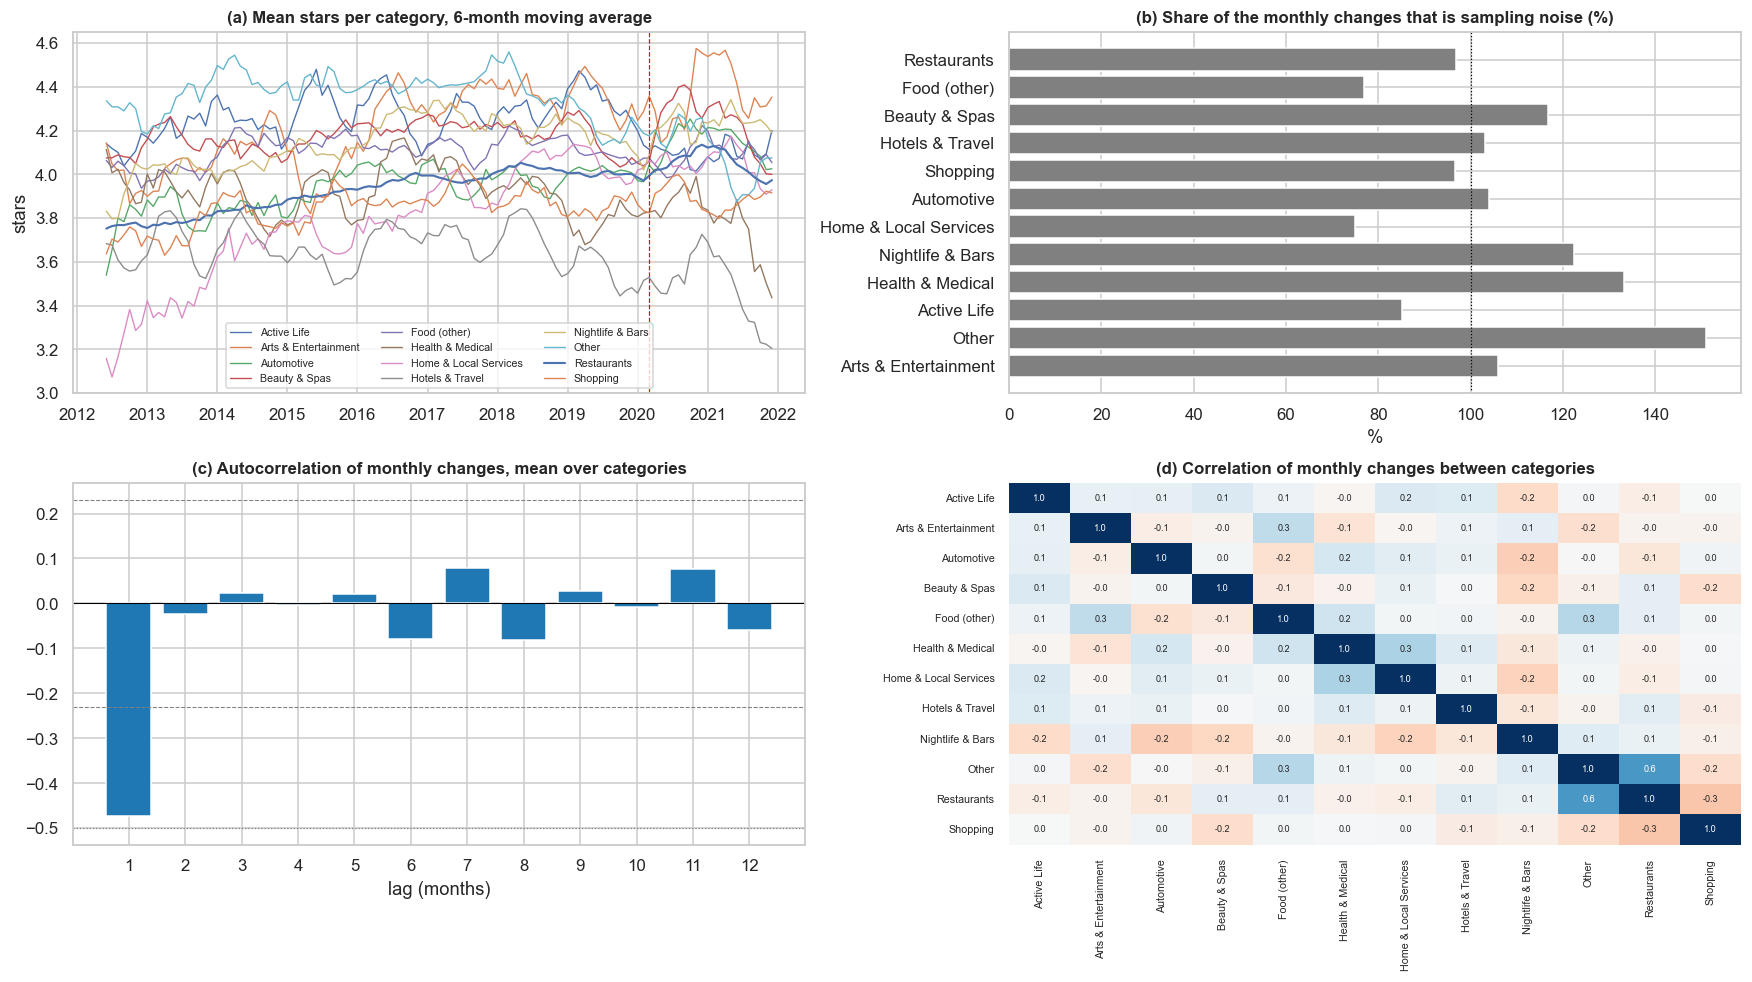

In [20]:
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.statespace.sarimax import SARIMAX

DIAG = np.arange(TS0, mi[pd.Period("2017-12", "M")] + 1)
didx = PM[DIAG].to_timestamp()
rows, dY = [], {}
for k, c in enumerate(CATS):
    s = pd.Series(ymean[k, DIAG], index=didx)
    stl = STL(s, period=12, robust=True).fit()
    d = s.diff().dropna(); dY[c] = d
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        rows.append({"category": c, "reviews per month (median)": float(np.median(Nc[k, DIAG])),
                     "trend strength": max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var()),
                     "seasonal strength": max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var()),
                     "ADF p, level": adfuller(s, autolag="AIC")[1], "KPSS p, level": kpss(s, regression="c", nlags="auto")[1],
                     "ADF p, change": adfuller(d, autolag="AIC")[1], "KPSS p, change": kpss(d, regression="c", nlags="auto")[1],
                     "noise share of monthly changes %": 100 * np.mean(within_var_c[k] / Nc[k, DIAG[1:]] + within_var_c[k] / Nc[k, DIAG[:-1]]) / d.var(),
                     "autocorrelation of changes, lag 1": d.autocorr(1)})
RESULTS["ts_category_diagnostics"] = pd.DataFrame(rows).set_index("category").sort_values("reviews per month (median)", ascending=False)
display(RESULTS["ts_category_diagnostics"].round(3))
dY = pd.DataFrame(dY)
acf_pool = np.array([np.nanmean([dY[c].autocorr(k) for c in CATS]) for k in range(1, 13)])
cc = dY.corr().values
print(f"Mean autocorrelation of monthly changes over categories, lags 1-3: {np.round(acf_pool[:3], 2).tolist()}")
print(f"Mean correlation of monthly changes between two categories: {cc[np.triu_indices(nC, 1)].mean():.2f}")
print("(KPSS p-values are bounded to the range 0.01-0.10.)")

fig, ax = plt.subplots(2, 2, figsize=(16, 9))
for k, c in enumerate(CATS):
    s = pd.Series(ymean[k, TS0:], index=PM[TS0:].to_timestamp()).rolling(6).mean()
    ax[0, 0].plot(s.index, s, lw=1.4 if c == "Restaurants" else .9, label=c)
ax[0, 0].axvline(COVID_START, color="red", ls="--", lw=.8); ax[0, 0].legend(ncol=3, fontsize=7)
ax[0, 0].set(title="(a) Mean stars per category, 6-month moving average", ylabel="stars")
x_ = RESULTS["ts_category_diagnostics"]
ax[0, 1].barh(x_.index[::-1], x_["noise share of monthly changes %"][::-1], color="grey")
ax[0, 1].axvline(100, color="black", ls=":", lw=.8)
ax[0, 1].set(title="(b) Share of the monthly changes that is sampling noise (%)", xlabel="%")
lg = np.arange(1, 13)
ax[1, 0].bar(lg, acf_pool, color="tab:blue"); ax[1, 0].axhline(0, color="black", lw=.7)
ax[1, 0].axhline(-.5, color="grey", ls=":", lw=.8); ax[1, 0].axhline(1.96 / np.sqrt(len(DIAG)), color="grey", ls="--", lw=.7); ax[1, 0].axhline(-1.96 / np.sqrt(len(DIAG)), color="grey", ls="--", lw=.7)
ax[1, 0].set(title="(c) Autocorrelation of monthly changes, mean over categories", xlabel="lag (months)", xticks=lg)
sns.heatmap(dY.corr(), cmap="RdBu", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 6}, ax=ax[1, 1], cbar=False)
ax[1, 1].set_title("(d) Correlation of monthly changes between categories"); ax[1, 1].tick_params(labelsize=7)
savefig("ts_category_diagnostics")

**Reading the diagnostics.**

* **Level.** Restaurants, with about 1,500 reviews a month, has a clear upward trend (trend strength 0.88, from about 3.75 to 4.05 stars) and a unit root (ADF p = 0.91, KPSS rejects stationarity). The smaller categories have weak trends; ADF rejects a unit root for 10 of the 12 categories, but KPSS also rejects stationarity for 9 of them, which is the typical sign of a series that is mostly stationary but drifts slowly. The monthly changes are stationary for every category.
* **Season.** Weak: the seasonal strength is below 0.2 for most categories and at most 0.42 (Home & Local Services), consistent with the failure of the seasonal naive baseline.
* **Noise.** Monthly changes are almost entirely sampling noise: the noise share is between 75 % and 151 %, around 100 % for most categories (panel b). The estimate treats the reviews of a month as a random sample; since the mix of businesses in a category changes little from month to month, it slightly overstates the noise, which is why it can exceed 100 %.
* **Autocorrelation.** The monthly change has an autocorrelation of -0.47 at lag 1 (between -0.36 and -0.58 per category) and almost none after that (panel c). This is close to the -0.50 of pure noise around a level: a good month is followed by an ordinary one.
* **Categories move independently.** The mean correlation of monthly changes between two categories is 0.01 (panel d); the only clear exception is Other with Restaurants (0.6). This correlation is real (it is the same in the raw data, and also 0.62 as a rank correlation, so it is not caused by a few months), although "Other" holds pets, events and photographers and shares no reviews with Restaurants; its cause is not known. Apart from it, there is no common monthly shock that one category could reveal about another.

**Consequences for the models.** Each series is a slowly moving level plus noise. A good forecast averages many months, which is exactly what the 12-month mean and ARIMA(0,1,1) (with a moving-average coefficient close to -1) do. Seasonal terms and inputs that try to explain month-to-month changes have little to work with.

### 6.3 Local ARIMA-type models: one model per category

Each category gets its own models, fitted only on its own monthly series from January 2012. At each forecast origin from December 2017 to November 2021, every model is refitted on the months up to the origin and forecasts the next month, so the forecasts cover exactly the test months of the other models.

| Model | Description | Role |
|---|---|---|
| **ARIMA(0,1,1)** | models the monthly change (`d = 1`) with one moving-average term, so the forecast is a weighted average of past months with more weight on recent ones | the **reference local model** |
| **SARIMA(0,1,1)(1,0,0,12)** | ARIMA(0,1,1) plus a yearly seasonal term | does a seasonal term help? |
| **ARIMAX + sentiment** | ARIMA(0,1,1) plus the 3-month change in text sentiment (`sent_dev3`) and in the sentiment-star gap (`gap_dev3`), as known last month | does the text lead the stars? |
| **ARIMAX + network** | ARIMA(0,1,1) plus the recent mood of the reviewers' friends (`net_friend_mood`) and the deviation of reviews written after a friend's review (`net_exposed_dev_3m`), as known last month | does the network lead the stars? |
| **ARIMAX + network PLACEBO** | the same inputs computed on the scrambled friendship graph | the control for ARIMAX + network (used in 7.1) |

An ARIMAX model on about 70-120 months cannot take dozens of inputs, so each group gets two, **chosen in advance** from the hypotheses of Sections 4.6 (the text turns before the stars) and 5.4 (friends' ratings pull a user's rating). Inputs are lagged by one month, so no future value is used. The orders are fixed in advance, so there are no hyperparameters to tune on 2014-2017. A fit that fails falls back on the mean of the last 12 months (the share is reported).

**Tests.** Two forecasts are compared with a **Diebold-Mariano test pooled over categories**: in each month the difference in squared error is averaged over the 12 categories (which absorbs the correlation between categories in the same month), and the mean over months is tested with a Newey-West variance (which allows for serial correlation).

In [21]:
ARIMAX_SENT = ["sent_dev3", "gap_dev3"]                  # recent change in text sentiment and in the text-star gap (Section 4.6)
ARIMAX_NET = ["net_friend_mood", "net_exposed_dev_3m"]   # friends' recent mood, and reviews that followed a friend's review (Section 5.4)
ARIMA_MODELS = {"ARIMA(0,1,1)": ((0, 0, 0, 0), ()), "SARIMA(0,1,1)(1,0,0,12)": ((1, 0, 0, 12), ()),
                "ARIMAX + sentiment": ((0, 0, 0, 0), tuple(ARIMAX_SENT)), "ARIMAX + network": ((0, 0, 0, 0), tuple(ARIMAX_NET)),
                "ARIMAX + network PLACEBO": ((0, 0, 0, 0), tuple("pl_" + c for c in ARIMAX_NET))}
print("ARIMAX inputs:", {k: v[1] for k, v in ARIMA_MODELS.items() if v[1]})
FEAT_ARR = {**HISTC, **SENTC, **{c: NETC_REAL[c].values.reshape(nC, nM) for c in NF_COLS}, **{"pl_" + c: NETC_PLAC[c].values.reshape(nC, nM) for c in NF_COLS}}
EXOGC = {k: FEAT_ARR[k] for spec in ARIMA_MODELS.values() for k in spec[1]}


def lagged_ffill(M):
    """Input known at the end of month t-1, used for month t; gaps keep the last known value.
    Months before the first value get 0 (no change): all ARIMAX inputs are deviations, and filling backwards would use later data."""
    out = pd.DataFrame(M).T.ffill().fillna(0).T.values
    return np.c_[np.full((len(M), 1), np.nan), out[:, :-1]]


EXOG_LAG = {k: lagged_ffill(v) for k, v in EXOGC.items()}


def arima_category(k, y, X, origins, base12):
    """Walk-forward forecasts for one category: at each origin, fit on the months up to it and forecast the next month."""
    warnings.filterwarnings("ignore")
    rows = []
    for o in origins:
        yt = y[TS0:o + 1]
        for name, (seas, ex) in ARIMA_MODELS.items():
            fb = False
            try:
                if ex:
                    Xa = np.column_stack([X[e][TS0:o + 2] for e in ex])
                    r = SARIMAX(yt, exog=Xa[:-1], order=(0, 1, 1), seasonal_order=seas, trend="n").fit(disp=False, maxiter=100)
                    f = float(np.asarray(r.forecast(1, exog=Xa[-1:]))[0])
                else:
                    f = float(np.asarray(SARIMAX(yt, order=(0, 1, 1), seasonal_order=seas, trend="n").fit(disp=False, maxiter=100).forecast(1))[0])
                if not np.isfinite(f):
                    raise ValueError("non-finite forecast")
            except Exception:
                f, fb = base12[o], True
            rows.append({"ci": k, "origin": o, "target_t": o + 1, "model": name, "pred": float(np.clip(f, 1, 5)), "fallback": fb})
    return rows


def compute_arima_cat():
    origins = [t_ - 1 for t_ in TEST_M]
    jobs = [(k, ymean[k], {e: v[k] for e, v in EXOG_LAG.items()}, origins, HISTC["stars_12m"][k]) for k in range(nC)]
    res_ = Parallel(n_jobs=N_JOBS)(delayed(arima_category)(*j) for j in jobs)
    return pd.DataFrame([r_ for rr in res_ for r_ in rr])


ARIMA_C = cached("cat_arima_h1", compute_arima_cat)
print(f"Fits that fell back on the 12-month mean: {100 * ARIMA_C['fallback'].mean():.1f} %")


def arima_preds(Dc):
    w = ARIMA_C.pivot_table(index=["ci", "target_t"], columns="model", values="pred")
    m = Dc[["ci", "target_t"]].merge(w.reset_index(), on=["ci", "target_t"], how="left")
    assert len(m) == len(Dc) and m[list(ARIMA_MODELS)].notna().all().all()
    return {k: m[k].values for k in ARIMA_MODELS}


A1 = arima_preds(TEST_C1)
preds_a = {**baselines(TEST_C1), **{k: v for k, v in A1.items() if "PLACEBO" not in k}}
RESULTS["cat_arima"] = score_table(preds_a, TEST_C1)
display(RESULTS["cat_arima"].round(4))

A_COMPARE = [("ARIMA(0,1,1)", "Mean of the last 12 months"), ("ARIMA(0,1,1)", "Last month"), ("SARIMA(0,1,1)(1,0,0,12)", "ARIMA(0,1,1)"),
             ("ARIMAX + sentiment", "ARIMA(0,1,1)"), ("ARIMAX + network", "ARIMA(0,1,1)")]
A_COMPARE = [(a, b) for a, b in A_COMPARE if a in preds_a and b in preds_a]
rows = []
for period, mask in (("before COVID", TEST_C1["target_t"] <= LAST_PRE_M), ("COVID", TEST_C1["target_t"] > LAST_PRE_M)):
    d, mk = TEST_C1[mask], mask.values
    for a, b in A_COMPARE:
        m_, lo, hi, p_ = dm_pooled(preds_a[a][mk], preds_a[b][mk], d)
        per_cat = pd.DataFrame({"c": d["ci"].values, "a": (d["y"].values - preds_a[a][mk]) ** 2, "b": (d["y"].values - preds_a[b][mk]) ** 2}).groupby("c").mean()
        rows.append({"period": period, "comparison": f"{a}  vs  {b}", "MSE change x 1000": 1000 * m_, "CI low": 1000 * lo, "CI high": 1000 * hi, "p": p_,
                     "% of MSE": 100 * m_ / mse(d["y"], preds_a[b][mk]), "categories where first is better": int((per_cat["a"] < per_cat["b"]).sum())})
RESULTS["cat_arima_tests"] = pd.DataFrame(rows).set_index(["period", "comparison"])
print("Negative = the first model has the lower error:")
display(RESULTS["cat_arima_tests"].round(3))

ARIMAX inputs: {'ARIMAX + sentiment': ('sent_dev3', 'gap_dev3'), 'ARIMAX + network': ('net_friend_mood', 'net_exposed_dev_3m'), 'ARIMAX + network PLACEBO': ('pl_net_friend_mood', 'pl_net_exposed_dev_3m')}
[cat_arima_h1] computed in 43 s
Fits that fell back on the 12-month mean: 0.0 %


RMSE     MAE    MASE  \
period                   model                                                
before COVID (2018-2019) Last month                  0.2087  0.1561  0.8610   
                         Mean of the last 12 months  0.1614  0.1237  0.7006   
                         Long-run mean               0.1892  0.1477  0.9031   
                         Seasonal naive              0.2175  0.1663  0.9462   
                         ARIMA(0,1,1)                0.1621  0.1199  0.6740   
                         SARIMA(0,1,1)(1,0,0,12)     0.1619  0.1213  0.6799   
                         ARIMAX + sentiment          0.1672  0.1241  0.6991   
                         ARIMAX + network            0.1635  0.1231  0.6904   
COVID (2020-2021)        Last month                  0.2806  0.2125  1.1926   
                         Mean of the last 12 months  0.2342  0.1776  1.0528   
                         Long-run mean               0.2650  0.2055  1.2317   
                         Seasonal naive              0.3206  0.2486  1.4903   
                         ARIMA(0,1,1)                0.2322  0.1760  1.0046   
                         SARIMA(0,1,1)(1,0,0,12)     0.2312  0.1767  1.0074   
                         ARIMAX + sentiment          0.2340  0.1756  1.0004   
                         ARIMAX + network            0.2338  0.1771  1.0095   

                                                     skill vs 12-month mean %  \
period                   model                                                  
before COVID (2018-2019) Last month                                  -67.0685   
                         Mean of the last 12 months                    0.0000   
                         Long-run mean                               -37.2932   
                         Seasonal naive                              -81.4456   
                         ARIMA(0,1,1)                                 -0.8785   
                         SARIMA(0,1,1)(1,0,0,12)                      -0.5788   
                         ARIMAX + sentiment                           -7.2430   
                         ARIMAX + network                             -2.6200   
COVID (2020-2021)        Last month                                  -43.5725   
                         Mean of the last 12 months                    0.0000   
                         Long-run mean                               -28.0486   
                         Seasonal naive                              -87.4363   
                         ARIMA(0,1,1)                                  1.6795   
                         SARIMA(0,1,1)(1,0,0,12)                       2.5143   
                         ARIMAX + sentiment                            0.1514   
                         ARIMAX + network                              0.3055   

                                                     share of predictable error removed %  \
period                   model                                                              
before COVID (2018-2019) Last month                                             -284.2299   
                         Mean of the last 12 months                                0.0000   
                         Long-run mean                                          -158.0448   
                         Seasonal naive                                         -345.1587   
                         ARIMA(0,1,1)                                             -3.7229   
                         SARIMA(0,1,1)(1,0,0,12)                                  -2.4529   
                         ARIMAX + sentiment                                      -30.6952   
                         ARIMAX + network                                        -11.1032   
COVID (2020-2021)        Last month                                              -91.5498   
                         Mean of the last 12 months                                0.0000   
                         Long-run mean                   

Negative = the first model has the lower error:


MSE change x 1000  \
period       comparison                                                        
before COVID ARIMA(0,1,1)  vs  Mean of the last 12 months              0.229   
             ARIMA(0,1,1)  vs  Last month                            -17.250   
             SARIMA(0,1,1)(1,0,0,12)  vs  ARIMA(0,1,1)                -0.078   
             ARIMAX + sentiment  vs  ARIMA(0,1,1)                      1.659   
             ARIMAX + network  vs  ARIMA(0,1,1)                        0.454   
COVID        ARIMA(0,1,1)  vs  Mean of the last 12 months             -0.921   
             ARIMA(0,1,1)  vs  Last month                            -24.810   
             SARIMA(0,1,1)(1,0,0,12)  vs  ARIMA(0,1,1)                -0.458   
             ARIMAX + sentiment  vs  ARIMA(0,1,1)                      0.838   
             ARIMAX + network  vs  ARIMA(0,1,1)                        0.753   

                                                           CI low  CI high  \
period       comparison                                                      
before COVID ARIMA(0,1,1)  vs  Mean of the last 12 months  -1.366    1.824   
             ARIMA(0,1,1)  vs  Last month                 -22.199  -12.301   
             SARIMA(0,1,1)(1,0,0,12)  vs  ARIMA(0,1,1)     -0.757    0.600   
             ARIMAX + sentiment  vs  ARIMA(0,1,1)           0.516    2.802   
             ARIMAX + network  vs  ARIMA(0,1,1)            -0.705    1.613   
COVID        ARIMA(0,1,1)  vs  Mean of the last 12 months  -4.806    2.965   
             ARIMA(0,1,1)  vs  Last month                 -35.437  -14.183   
             SARIMA(0,1,1)(1,0,0,12)  vs  ARIMA(0,1,1)     -1.835    0.920   
             ARIMAX + sentiment  vs  ARIMA(0,1,1)          -0.884    2.559   
             ARIMAX + network  vs  ARIMA(0,1,1)            -1.011    2.517   

                                                               p  % of MSE  \
period       comparison                                                      
before COVID ARIMA(0,1,1)  vs  Mean of the last 12 months  0.781     0.878   
             ARIMA(0,1,1)  vs  Last month                  0.000   -39.618   
             SARIMA(0,1,1)(1,0,0,12)  vs  ARIMA(0,1,1)     0.824    -0.297   
             ARIMAX + sentiment  vs  ARIMA(0,1,1)          0.009     6.309   
             ARIMAX + network  vs  ARIMA(0,1,1)            0.451     1.726   
COVID        ARIMA(0,1,1)  vs  Mean of the last 12 months  0.647    -1.680   
             ARIMA(0,1,1)  vs  Last month                  0.000   -31.519   
             SARIMA(0,1,1)(1,0,0,12)  vs  ARIMA(0,1,1)     0.521    -0.849   
             ARIMAX + sentiment  vs  ARIMA(0,1,1)          0.350     1.554   
             ARIMAX + network  vs  ARIMA(0,1,1)            0.411     1.397   

                                                           categories where first is better  
period       comparison                                                                      
before COVID ARIMA(0,1,1)  vs  Mean of the last 12 months                                 6  
             ARIMA(0,1,1)  vs  Last month                                                12  
             SARIMA(0,1,1)(1,0,0,12)  vs  ARIMA(0,1,1)                                    6  
             ARIMAX + sentiment  vs  ARIMA(0,1,1)                                         2  
             ARIMAX + network  vs  ARIMA(0,1,1)                                           2  
COVID        ARIMA(0,1,1)  vs  Mean of the last 12 months                                 7  
             ARIMA(0,1,1)  vs  Last month                                                11  
             SARIMA(0,1,1)(1,0,0,12)  vs  ARIMA(0,1,1)                                    6  
             ARIMAX + sentiment  vs  ARIMA(0,1,1)                                         4  
             ARIMAX + network  vs  ARIMA(0,1,1)                                           2

**Reading the results.**

* **ARIMA(0,1,1) behaves like the 12-month mean.** RMSE 0.162 against 0.161 before COVID (p = 0.78) and 0.232 against 0.234 during COVID (p = 0.65); it is better in 6 and 7 of the 12 categories, so neither wins. This is expected: with a moving-average coefficient close to -1, ARIMA(0,1,1) forecasts a weighted average of past months, which is what the 12-month mean is.
* **Averaging is essential.** ARIMA(0,1,1) cuts the error of "last month" by 40 % of MSE before COVID and 32 % during COVID (p < 0.001), in 12 and 11 of the 12 categories.
* **No useful season.** SARIMA changes the error by less than 1 % (p = 0.82 and 0.52), consistent with the weak seasonal strength in 6.2.
* **The text does not lead the stars.** ARIMAX + sentiment is *worse* than ARIMA: +6.3 % MSE before COVID (p = 0.009; better in only 2 categories) and +1.6 % during COVID (p = 0.35). The recent changes in text sentiment and in the gap add noise rather than information. This is also the direct test of the warning-signal hypothesis of Section 4.6: `gap_dev3` measures whether the text has recently turned more negative than the stars, and at the category level it does not announce lower stars.
* **Neither does the network.** ARIMAX + network is slightly worse than ARIMA (+1.7 % and +1.4 %, not significant), better in only 2 categories in each period.
* No fit failed, so no forecast fell back on the 12-month mean.

The local models confirm the diagnosis of 6.2: each series is a slowly moving level plus noise, so the best forecast is a long average, and inputs that try to explain monthly movements make the forecast worse.


### 6.4 Global forecasting models and walk-forward evaluation

Instead of one model per category, a single model is trained on the rows of all categories, so that what is learned in one category can be used for the others. Two models are used, both predicting the *difference* from the mean of the last 12 months, so a model that finds nothing falls back on that baseline:

* **Ridge regression**, linear and regularised (a careful linear baseline).
* **LightGBM**, gradient-boosted trees, able to capture nonlinearities and interactions.

For each test month, the models are refitted on all rows whose target is known at the forecast origin. Their hyperparameters (the LightGBM settings and the Ridge penalty) are chosen on 2014-2017 with the same walk-forward, using all the inputs of the three groups. Each model is then fitted with six sets of inputs: history alone, history plus sentiment, history plus network, all three groups, and the two network sets again with the placebo network, for the comparisons in Section 7.

In [22]:
import lightgbm as lgb
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

LGB_THREADS = 8


def fit_predict_lgb(tr, te, cols, params, threads=LGB_THREADS):
    m = lgb.LGBMRegressor(objective="regression", verbosity=-1, random_state=SEED, n_jobs=threads, subsample=.8, subsample_freq=1, colsample_bytree=.6, **params)
    m.fit(tr[cols], tr["resid"])
    return te["base"].values + m.predict(te[cols])


def fit_predict_ridge(tr, te, cols, alpha):
    cols = [c for c in cols if c != "cat"]
    if not cols:
        return te["base"].values
    m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=alpha))
    m.fit(tr[cols], tr["resid"])
    return te["base"].values + m.predict(te[cols])


def walk_forward(Dc, cols, kind, params, targets, h=1, threads=LGB_THREADS):
    """For each target month t_, train on the rows whose target is known at the origin t_ - h, and predict month t_.
    With no inputs, the forecast is the baseline itself."""
    out = np.full(len(Dc), np.nan)
    tt = Dc["target_t"].values
    for t_ in targets:
        sel = np.flatnonzero(tt == t_)
        tr = Dc[(tt <= t_ - h) & Dc["resid"].notna().values]
        if not len(sel) or len(tr) < 50:
            continue
        te = Dc.iloc[sel]
        if not cols:
            out[sel] = te["base"].values
        elif kind == "lgb":
            out[sel] = fit_predict_lgb(tr, te, cols, params, threads)
        else:
            out[sel] = fit_predict_ridge(tr, te, cols, params)
    return out


# input sets: each group enters with all its inputs
PL_COLS = ["pl_" + c for c in NF_COLS]
FEATURE_SETS = {"History": H_COLS, "History + sentiment": H_COLS + S_COLS, "History + network": H_COLS + NF_COLS,
                "History + sentiment + network": H_COLS + S_COLS + NF_COLS,
                "History + network PLACEBO": H_COLS + PL_COLS, "History + sentiment + network PLACEBO": H_COLS + S_COLS + PL_COLS}
ALL_COLS = FEATURE_SETS["History + sentiment + network"]
print("Inputs per model:", {k: len(v) for k, v in FEATURE_SETS.items()})


Inputs per model: {'History': 17, 'History + sentiment': 47, 'History + network': 24, 'History + sentiment + network': 54, 'History + network PLACEBO': 24, 'History + sentiment + network PLACEBO': 54}


In [23]:
GRID = [dict(n_estimators=n, learning_rate=lr, num_leaves=l, min_child_samples=c, reg_lambda=5)
        for n, lr in ((200, .03), (500, .01)) for l in (4, 8) for c in (10, 30)]
vmask = C1["target_t"].isin(VAL_M).values


def tune():
    rows = []
    for g in GRID:
        p = walk_forward(C1, ALL_COLS, "lgb", g, VAL_M)
        rows.append({"model": "lgb", **g, "MSE": mse(C1["y"][vmask], p[vmask])})
    for a in (1.0, 10.0, 100.0, 1000.0):
        p = walk_forward(C1, ALL_COLS, "ridge", a, VAL_M)
        rows.append({"model": "ridge", "alpha": a, "MSE": mse(C1["y"][vmask], p[vmask])})
    return pd.DataFrame(rows)


TUNE = cached("cat_tuning_all", tune)
best_l = TUNE[TUNE["model"] == "lgb"].sort_values("MSE").iloc[0]
LGB_PARAMS = {k: (float(best_l[k]) if k == "learning_rate" else int(best_l[k])) for k in GRID[0]}
RIDGE_ALPHA = float(TUNE[TUNE["model"] == "ridge"].sort_values("MSE").iloc[0]["alpha"])
v_ = C1[vmask]
print(f"Chosen on 2014-2017: LightGBM {LGB_PARAMS} (validation RMSE {np.sqrt(best_l['MSE']):.4f}); Ridge alpha = {RIDGE_ALPHA:g}; "
      f"12-month mean on validation: RMSE {np.sqrt(mse(v_['y'], v_['base'])):.4f}")


def compute_wf():
    out = C1[["ci", "target_t", "y", "n", "base"]].copy()
    for name, cols in FEATURE_SETS.items():
        out[f"LGBM | {name}"] = walk_forward(C1, cols, "lgb", LGB_PARAMS, TEST_M)
    for name in ("History", "History + sentiment", "History + network", "History + sentiment + network"):
        out[f"Ridge | {name}"] = walk_forward(C1, FEATURE_SETS[name], "ridge", RIDGE_ALPHA, TEST_M)
    return out[out["target_t"].isin(TEST_M)].reset_index(drop=True)


WF1 = cached("cat_walk_forward_all_h1", compute_wf)
assert (WF1[["ci", "target_t"]].values == TEST_C1[["ci", "target_t"]].values).all()
preds = {**baselines(TEST_C1), **{k: v for k, v in A1.items() if "PLACEBO" not in k}, **{c: WF1[c].values for c in WF1.columns if "|" in c}}
RESULTS["cat_h1"] = score_table(preds, TEST_C1)
display(RESULTS["cat_h1"].sort_values(["period", "RMSE"]).round(4))

Chosen on 2014-2017: LightGBM {'n_estimators': 500, 'learning_rate': 0.01, 'num_leaves': 4, 'min_child_samples': 10, 'reg_lambda': 5} (validation RMSE 0.1814); Ridge alpha = 1000; 12-month mean on validation: RMSE 0.1790


RMSE  \
period                   model                                                  
COVID (2020-2021)        LGBM | History + network                      0.2295   
                         LGBM | History + network PLACEBO              0.2302   
                         LGBM | History                                0.2310   
                         SARIMA(0,1,1)(1,0,0,12)                       0.2312   
                         Ridge | History + sentiment                   0.2313   
                         LGBM | History + sentiment + network          0.2314   
                         Ridge | History + sentiment + network         0.2315   
                         LGBM | History + sentiment + network PLACEBO  0.2316   
                         LGBM | History + sentiment                    0.2317   
                         Ridge | History + network                     0.2317   
                         Ridge | History                               0.2321   
                         ARIMA(0,1,1)                                  0.2322   
                         ARIMAX + network                              0.2338   
                         ARIMAX + sentiment                            0.2340   
                         Mean of the last 12 months                    0.2342   
                         Long-run mean                                 0.2650   
                         Last month                                    0.2806   
                         Seasonal naive                                0.3206   
before COVID (2018-2019) LGBM | History + network PLACEBO              0.1586   
                         Ridge | History + sentiment + network         0.1591   
                         LGBM | History                                0.1592   
                         LGBM | History + network                      0.1593   
                         Ridge | History + sentiment                   0.1594   
                         Ridge | History + network                     0.1595   
                         LGBM | History + sentiment + network PLACEBO  0.1600   
                         LGBM | History + sentiment                    0.1600   
                         Ridge | History                               0.1601   
                         LGBM | History + sentiment + network          0.1609   
                         Mean of the last 12 months                    0.1614   
                         SARIMA(0,1,1)(1,0,0,12)                       0.1619   
                         ARIMA(0,1,1)                                  0.1621   
                         ARIMAX + network                              0.1635   
                         ARIMAX + sentiment                            0.1672   
                         Long-run mean                                 0.1892   
                         Last month                                    0.2087   
                         Seasonal naive                                0.2175   

                                                                          MAE  \
period                   model                                                  
COVID (2020-2021)        LGBM | History + network                      0.1741   
                         LGBM | History + network PLACEBO              0.1765   
                         LGBM | History                                0.1761   
                         SARIMA(0,1,1)(1,0,0,12)                       0.1767   
                         Ridge | History + sentiment                   0.1754   
                         LGBM | History + sentiment + network          0.1754   
                         Ridge | History + sentiment + network         0.1755   
                         LGBM | History + sentiment + network PLACEBO  0.1771   
                         LGBM | History + sentiment                    0.1759   
                         Ridge | History + network                     0.1759   
                      

Negative = the first model has the lower error:


MSE change x 1000  \
period       comparison                                                              
before COVID LGBM | History  vs  Mean of the last 12 months                 -0.722   
             LGBM | History + sentiment  vs  LGBM | History                  0.270   
             LGBM | History + network  vs  LGBM | History                    0.031   
             LGBM | History + sentiment + network  vs  LGBM ...              0.270   
             LGBM | History + network  vs  LGBM | History + ...              0.206   
             LGBM | History + sentiment + network  vs  LGBM ...              0.294   
             Ridge | History + sentiment  vs  Ridge | History               -0.215   
             Ridge | History + network  vs  Ridge | History                 -0.167   
             ARIMAX + network  vs  ARIMAX + network PLACEBO                 -2.128   
COVID        LGBM | History  vs  Mean of the last 12 months                 -1.457   
             LGBM | History + sentiment  vs  LGBM | History                  0.300   
             LGBM | History + network  vs  LGBM | History                   -0.701   
             LGBM | History + sentiment + network  vs  LGBM ...             -0.137   
             LGBM | History + network  vs  LGBM | History + ...             -0.316   
             LGBM | History + sentiment + network  vs  LGBM ...             -0.093   
             Ridge | History + sentiment  vs  Ridge | History               -0.365   
             Ridge | History + network  vs  Ridge | History                 -0.177   
             ARIMAX + network  vs  ARIMAX + network PLACEBO                 -0.350   

                                                                 CI low  \
period       comparison                                                   
before COVID LGBM | History  vs  Mean of the last 12 months      -1.516   
             LGBM | History + sentiment  vs  LGBM | History      -0.364   
             LGBM | History + network  vs  LGBM | History        -0.472   
             LGBM | History + sentiment + network  vs  LGBM ...   0.033   
             LGBM | History + network  vs  LGBM | History + ...  -0.921   
             LGBM | History + sentiment + network  vs  LGBM ...  -0.491   
             Ridge | History + sentiment  vs  Ridge | History    -0.688   
             Ridge | History + network  vs  Ridge | History      -0.422   
             ARIMAX + network  vs  ARIMAX + network PLACEBO      -3.798   
COVID        LGBM | History  vs  Mean of the last 12 months      -4.865   
             LGBM | History + sentiment  vs  LGBM | History      -1.455   
             LGBM | History + network  vs  LGBM | History        -1.734   
             LGBM | History + sentiment + network  vs  LGBM ...  -0.731   
             LGBM | History + network  vs  LGBM | History + ...  -2.575   
             LGBM | History + sentiment + network  vs  LGBM ...  -2.082   
             Ridge | History + sentiment  vs  Ridge | History    -2.135   
             Ridge | History + network  vs  Ridge | History      -0.974   
             ARIMAX + network  vs  ARIMAX + network PLACEBO      -2.748   

                                                                 CI high  \
period       comparison                                                    
before COVID LGBM | History  vs  Mean of the last 12 months        0.072   
             LGBM | History + sentiment  vs  LGBM | History        0.903   
             LGBM | History + network  vs  LGBM | History          0.534   
             LGBM | History + sentiment + network  vs  LGBM ...    0.507   
             LGBM | History + network  vs  LGBM | History + ...    1.333   
             LGBM | History + sentiment + network  vs  LGBM ...    1.079   
             Ridge | History + sentiment  vs  Ridge | History      0.258   
             Ridge | History + network  vs  Ridge | History        0.088   
             ARIMAX + network  vs  ARIMAX + network PLACEBO       -0.458   
COVID  

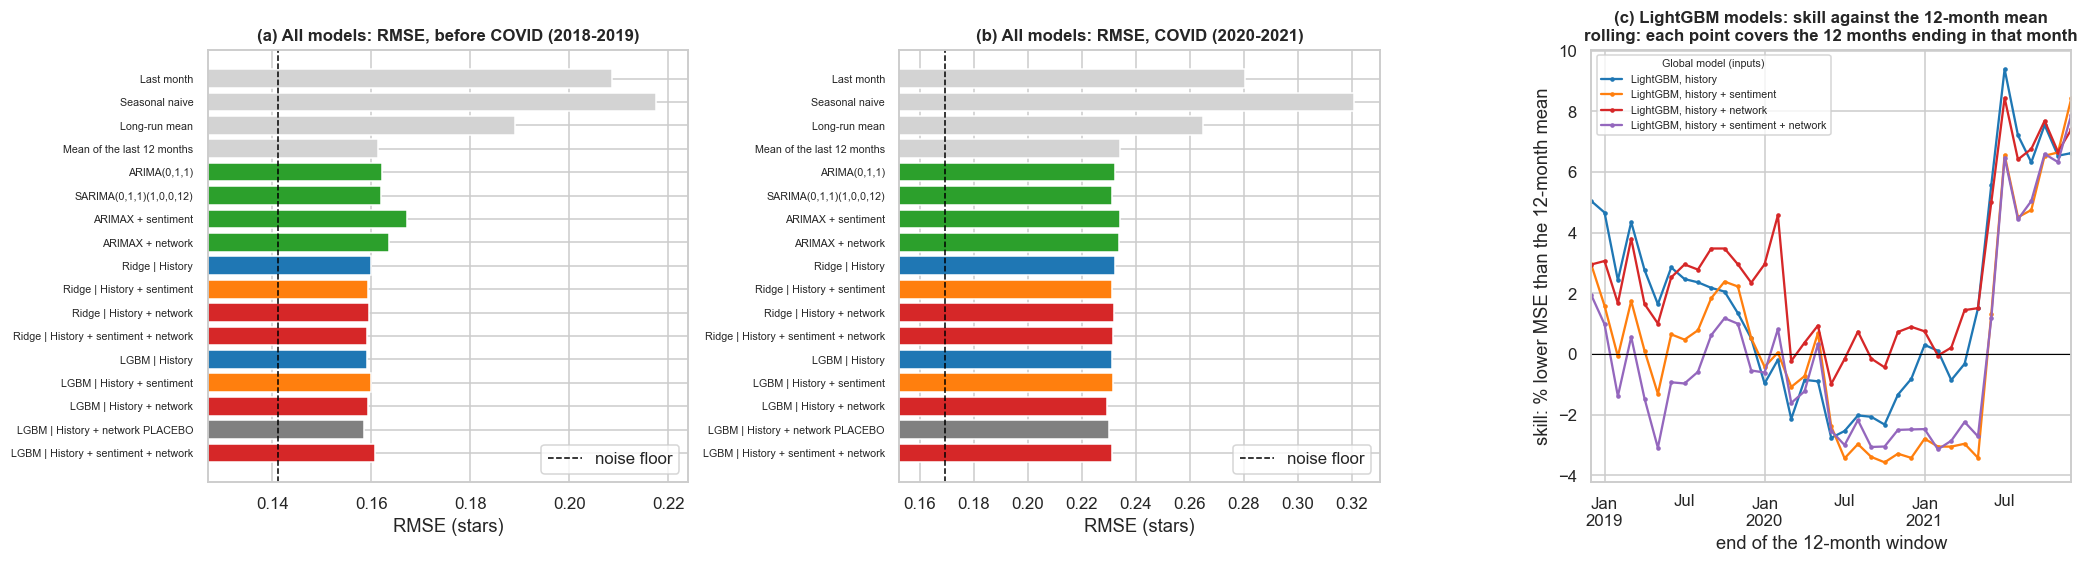

In [24]:
COMPARE = [("LGBM | History", "Mean of the last 12 months"), ("LGBM | History + sentiment", "LGBM | History"), ("LGBM | History + network", "LGBM | History"),
           ("LGBM | History + sentiment + network", "LGBM | History + sentiment"), ("LGBM | History + network", "LGBM | History + network PLACEBO"),
           ("LGBM | History + sentiment + network", "LGBM | History + sentiment + network PLACEBO"), ("Ridge | History + sentiment", "Ridge | History"),
           ("Ridge | History + network", "Ridge | History"), ("ARIMAX + network", "ARIMAX + network PLACEBO")]
pool = {**preds, **{k: v for k, v in A1.items() if "PLACEBO" in k}}
COMPARE = [(a, b) for a, b in COMPARE if a in pool and b in pool]
rows = []
for period, mask in (("before COVID", TEST_C1["target_t"] <= LAST_PRE_M), ("COVID", TEST_C1["target_t"] > LAST_PRE_M)):
    d, mk = TEST_C1[mask], mask.values
    for a, b in COMPARE:
        m_, lo, hi, p_ = dm_pooled(pool[a][mk], pool[b][mk], d)
        rows.append({"period": period, "comparison": f"{a}  vs  {b}", "MSE change x 1000": 1000 * m_, "CI low": 1000 * lo, "CI high": 1000 * hi, "p": p_,
                     "% of MSE": 100 * m_ / mse(d["y"], pool[b][mk])})
RESULTS["cat_ablation_tests"] = pd.DataFrame(rows).set_index(["period", "comparison"])
print("Negative = the first model has the lower error:")
display(RESULTS["cat_ablation_tests"].round(3))

t = RESULTS["cat_h1"].reset_index()
order = ["Last month", "Seasonal naive", "Long-run mean", "Mean of the last 12 months", *[k for k in ARIMA_MODELS if "PLACEBO" not in k],
         "Ridge | History", "Ridge | History + sentiment", "Ridge | History + network", "Ridge | History + sentiment + network",
         "LGBM | History", "LGBM | History + sentiment", "LGBM | History + network", "LGBM | History + network PLACEBO", "LGBM | History + sentiment + network"]


def colour(n):
    if "ARIMA" in n:
        return "tab:green"
    if "|" not in n:
        return "lightgrey"
    return "grey" if "PLACEBO" in n else "tab:red" if "network" in n else "tab:orange" if "sentiment" in n else "tab:blue"


fig, ax = plt.subplots(1, 3, figsize=(19, 5.2))
for k_, (a_, per) in enumerate(zip(ax[:2], t["period"].unique())):
    x = t[t["period"] == per].set_index("model").reindex(order)
    a_.barh(x.index[::-1], x["RMSE"][::-1], color=[colour(n) for n in x.index[::-1]])
    a_.axvline(x["noise floor RMSE"].iloc[0], color="black", ls="--", lw=1, label="noise floor")
    a_.set_xlim(x["noise floor RMSE"].iloc[0] * .9, x["RMSE"].max() * 1.03); a_.legend()
    a_.set(title=f"({'ab'[k_]}) All models: RMSE, {per}", xlabel="RMSE (stars)"); a_.tick_params(axis="y", labelsize=7)
mm = pd.DataFrame({"t": TEST_C1["target_t"].values, "y": TEST_C1["y"].values, "base": TEST_C1["base"].values,
                   **{n: preds[f"LGBM | {n}"] for n in ("History", "History + sentiment", "History + network", "History + sentiment + network")}})
by = mm.groupby("t")
sk = pd.DataFrame({n: 100 * (1 - by.apply(lambda g: mse(g["y"], g[n])).rolling(12).sum() / by.apply(lambda g: mse(g["y"], g["base"])).rolling(12).sum())
                   for n in ("History", "History + sentiment", "History + network", "History + sentiment + network")})
sk = sk.dropna()                                          # each point needs 12 test months, so the first point is December 2018
sk.index = PM[sk.index].to_timestamp()
sk.columns = [f"LightGBM, {n.lower()}" for n in sk.columns]
sk.plot(ax=ax[2], marker="o", ms=2, color=["tab:blue", "tab:orange", "tab:red", "tab:purple"])   # same colours as the bars in (a) and (b)
ax[2].axhline(0, color="black", lw=.7)
ax[2].legend(title="Global model (inputs)", fontsize=7, title_fontsize=7)
ax[2].set(title="(c) LightGBM models: skill against the 12-month mean\nrolling: each point covers the 12 months ending in that month",
          xlabel="end of the 12-month window", ylabel="skill: % lower MSE than the 12-month mean")
savefig("category_results")

**Reading the results.**

* **Tuning.** The chosen LightGBM is small and slow-learning (500 trees, learning rate 0.01, 4 leaves), and Ridge picks the strongest penalty offered (alpha = 1,000): the validation data favour models that stay close to the 12-month mean. Even so, the best LightGBM has a validation RMSE of 0.181 against 0.179 for the 12-month mean, so **on 2014-2017 no global model beats the baseline**.
* **Test years.** On 2018-2021 the global models are 2-4 % better in MSE than the 12-month mean: before COVID, LightGBM with history 0.159 (+2.8 %) and Ridge with all inputs 0.159 (+2.9 %); during COVID, LightGBM with history and network 0.230 (+3.9 %). They remove at most about 12-15 % of the error that is not sampling noise: the noise floor is 0.141 before COVID and 0.170 during COVID.
* **None of these gains is reliable.** LightGBM with history against the 12-month mean: -2.8 % (p = 0.09) before COVID and -2.7 % (p = 0.41) during COVID. Since the gain did not appear on the validation years either, it is best read as luck in the test years.
* **Sentiment adds nothing.** Adding the 30 sentiment inputs makes LightGBM slightly worse (+1.1 % and +0.6 % MSE, not significant). Ridge improves slightly with them (-0.8 % and -0.7 %, p = 0.38 and 0.69).
* **The network adds nothing beyond its placebo.** Adding the network inputs to history changes the error by +0.1 % (p = 0.91) and -1.3 % (p = 0.20). The scrambled network does as well as the real one, and before COVID even slightly better (0.1586, +3.4 %, the lowest RMSE of all). Every LightGBM comparison of the real against the placebo network has p between 0.47 and 0.93.
* **The two "significant" results are not evidence of a network effect.** Adding the network to history + sentiment makes LightGBM *worse* before COVID (+1.1 %, p = 0.036). ARIMAX + network beats its placebo before COVID (-7.4 %, p = 0.02), but only because the placebo inputs harm ARIMA more; ARIMAX + network is itself worse than ARIMA without inputs. With 18 comparisons, one or two p-values below 0.05 are expected by chance.

**The figure.**

* **(a) and (b): RMSE of every model**, before and during COVID. This includes the baselines (light grey), ARIMA-type models (green), Ridge and LightGBM, coloured by inputs: blue history, orange sentiment, red network, dark grey placebo. The dashed line is the noise floor. In both periods all model bars end at almost the same place, just to the right of the noise floor. The simple baselines (last month, seasonal naive, long-run mean) are clearly worse.
* **(c): skill of the four LightGBM models only**, one line per set of inputs, in the colours of (a) and (b) (purple = all three groups). Skill is the percentage reduction in MSE against the 12-month mean (above 0 = better than the baseline). Each point covers the 12 test months ending in that month, so the first point is December 2018 (the year 2018) and the last December 2021 (the year 2021). Errors are averaged over the 12 categories, each counting equally. Ridge, ARIMA and the placebo models are not drawn here; their results are in the tables above.

The rolling skill is unstable. It lies between -3 % and +5 % in 2019 and around or below zero for every model from 2020 to early 2021: history + network stays close to 0, the others fall to about -3.5 %. It then jumps to +4 to +9 % for all four in the second half of 2021, ending at +7 to +8 %. That last jump comes when the 12-month mean still contains the unusual COVID months and lags the return to normal, so any model that reacts to recent months gains for a while. **The gains depend on the period, not on which inputs the model has.**


## 7. Integration: does the network help to forecast the stars?

This is the core of the project. Section 6 trained the same forecasting models with different groups of inputs. If network inputs reduce the error on unseen months, the social network holds predictive information about the ratings of a category.

Two safeguards keep this honest:

1. **Pooled Diebold-Mariano test** (6.3): differences in error are averaged over categories within each month and tested over the 48 test months with a Newey-West variance, because categories in the same month share shocks and errors are correlated over time.
2. **Placebo network.** The same inputs are computed on a **scrambled** friendship graph (user identities shuffled, keeping the degree distribution). A real network effect must beat the placebo. If the placebo does equally well, the gain has nothing to do with who is connected to whom.



### 7.1 Is a network effect visible in the category series?

**Are the network inputs simply broken?** A null result could also come from faulty inputs, so each one is checked on its own: its correlation with the next-month surprise (stars minus the 12-month mean) within months, for the real and the scrambled graph, using only rows before the test period. A real input should be more correlated than its placebo.

The second calculation asks **how large an effect could be expected at all**. It multiplies the conformity effect from Section 5.4 by the share of reviews with a recent friend review and by the typical size of a friend's deviation, and compares it with the sampling noise of a category's monthly mean.

In [25]:
chk = C1[C1["target_t"] < TEST_M[0]]
rows = []
for c_ in NF_COLS:
    x_ = chk[["resid", c_, "pl_" + c_, "t"]].dropna()
    real = x_[c_] - x_.groupby("t")[c_].transform("mean"); plc = x_["pl_" + c_] - x_.groupby("t")["pl_" + c_].transform("mean")
    res_ = x_["resid"] - x_.groupby("t")["resid"].transform("mean")
    rows.append({"input": c_, "corr, real graph": np.corrcoef(real, res_)[0, 1] if real.std() > 0 else np.nan,
                 "corr, placebo graph": np.corrcoef(plc, res_)[0, 1] if plc.std() > 0 else np.nan, "rows": len(x_)})
RESULTS["cat_network_feature_check"] = pd.DataFrame(rows).set_index("input")
display(RESULTS["cat_network_feature_check"].round(3))
print(f"With {len(x_)} rows, a correlation needs to exceed about {1.96 / np.sqrt(len(x_)):.2f} in size to differ from 0 at the 5 % level.")

recent = RESULTS["conformity_by_lag"].loc["1-30 days", "friend"]
share_recent = float(((P["lag"] >= 1) & (P["lag"] <= 30)).sum() / (R["prior_n"] >= 5).sum())
sd_dev = float(P.loc[P["lag"].between(1, 30), "x_f"].std())
exp_shift = recent * share_recent * sd_dev
nf_all = np.sqrt(noise_floor(TEST_C1))
nf_rest = np.sqrt(noise_floor(TEST_C1[TEST_C1["ci"] == ci_of["Restaurants"]]))
print(f"Conformity 1-30 days: {recent:.2f} | share of reviews with such a friend review: {share_recent:.2%} | SD of a friend's deviation: {sd_dev:.2f} stars")
print(f"Typical shift of a category's monthly mean from this channel: about {exp_shift:.4f} stars, against sampling noise of {nf_all:.3f} stars "
      f"(all categories) and {nf_rest:.3f} stars (Restaurants)")

,"corr, real graph","corr, placebo graph",rows
input,,,
net_ld_3m,-0.023,-0.019,720
net_conn_3m,-0.036,-0.015,720
net_exposed_3m,-0.019,-0.031,720
net_exposed_dev_3m,0.065,-0.021,257
net_pr_stars_gap,0.025,-0.064,720
net_friend_mood,-0.020,0.030,715
net_audience_generosity,0.009,0.006,720


With 720 rows, a correlation needs to exceed about 0.07 in size to differ from 0 at the 5 % level.
Conformity 1-30 days: 0.37 | share of reviews with such a friend review: 1.30% | SD of a friend's deviation: 1.00 stars
Typical shift of a category's monthly mean from this channel: about 0.0049 stars, against sampling noise of 0.156 stars (all categories) and 0.033 stars (Restaurants)


**Reading the check.** No network input is meaningfully correlated with the next-month surprise: all correlations are below 0.07 in size, the threshold for significance with 720 rows (and net_exposed_dev_3m, at 0.065, has only 257 rows, for which the threshold is about 0.12). The placebo inputs are just as correlated. The calculation explains why: conformity is strong for one person (0.37), but only about 1.3 % of reviews follow a friend's review within 30 days, so the channel shifts a monthly mean by about **0.005 stars**. The sampling noise of a category's monthly mean is about 0.16 stars on average and 0.03 even for Restaurants. Aggregating businesses into categories reduces the noise a lot, but not nearly enough to reveal an effect of that size.

### 7.2 Where the network does help: individual ratings

If the channel is too thin to move a category's monthly mean, it might still appear at the level of a single person. This is tested with the same discipline (train on the past, test on the future, placebo).

**One person's next rating.** For reviews preceded by a friend's review of the same business (at least one day before), we train before 2018 and test on 2018-2019. Does knowing what the friend said reduce the error, beyond the business's mean and the user's generosity? The placebo is a matched non-friend's review of the same business.

In [26]:
Pf = P[P["lag"] >= 1].copy()
Pf["date"] = R.loc[Pf["rid"].values, "date"].values
Pf["recent"] = (Pf["lag"] <= 30).astype(float)
Pf["x_f_recent"] = Pf["x_f"] * Pf["recent"]; Pf["x_n_recent"] = Pf["x_n"] * Pf["recent"]
Pf_tr, Pf_te = Pf[Pf["date"] < "2018-01-01"], Pf[(Pf["date"] >= "2018-01-01") & (Pf["date"] < "2020-01-01")]
SPEC = {"Business mean": ["pm"], "+ user generosity": ["pm", "len_v"], "+ non-friend's rating (placebo)": ["pm", "len_v", "x_n", "x_n_recent"], "+ friend's rating": ["pm", "len_v", "x_f", "x_f_recent", "len_f"],
        "+ both": ["pm", "len_v", "x_n", "x_n_recent", "x_f", "x_f_recent", "len_f"]}
pred_ind, rows = {}, []
for name, cols_ in SPEC.items():
    fit = sm.OLS(Pf_tr["y"], sm.add_constant(Pf_tr[cols_])).fit()
    pred_ind[name] = np.clip(fit.predict(sm.add_constant(Pf_te[cols_], has_constant="add")).values, 1, 5)
    for grp, mask in (("all friends", np.ones(len(Pf_te), bool)), ("friend within 30 days", Pf_te["recent"].values == 1)):
        rows.append({"inputs": name, "reviews": grp, "RMSE": np.sqrt(np.mean((Pf_te["y"].values[mask] - pred_ind[name][mask]) ** 2)), "n": int(mask.sum())})
RESULTS["individual_forecast"] = pd.DataFrame(rows).pivot(index="inputs", columns="reviews", values="RMSE").reindex(list(SPEC))
display(RESULTS["individual_forecast"].round(4))


def boot_user(a, b, df, n=1000):
    g = pd.DataFrame({"u": df["u"].values, "d": (df["y"].values - a) ** 2 - (df["y"].values - b) ** 2}).groupby("u")["d"].agg(["sum", "size"])
    rng_ = np.random.default_rng(SEED)
    bs = [g["sum"].values[i_].sum() / g["size"].values[i_].sum() for i_ in (rng_.integers(0, len(g), len(g)) for _ in range(n))]
    return g["sum"].sum() / g["size"].sum(), np.percentile(bs, 2.5), np.percentile(bs, 97.5)


rows = []
for a_, b_ in (("+ friend's rating", "+ user generosity"), ("+ non-friend's rating (placebo)", "+ user generosity"), ("+ friend's rating", "+ non-friend's rating (placebo)")):
    m_, lo, hi = boot_user(pred_ind[a_], pred_ind[b_], Pf_te)
    rows.append({"comparison": f"{a_} vs {b_}", "MSE change": m_, "CI low": lo, "CI high": hi, "reviews": len(Pf_te)})
RESULTS["individual_forecast_tests"] = pd.DataFrame(rows).set_index("comparison")
display(RESULTS["individual_forecast_tests"].round(4))

reviews,all friends,friend within 30 days
inputs,,
Business mean,1.0297,0.9567
+ user generosity,1.0013,0.9456
+ non-friend's rating (placebo),1.0012,0.9423
+ friend's rating,0.9871,0.8641
+ both,0.9872,0.8618


,MSE change,CI low,CI high,reviews
comparison,,,,
+ friend's rating vs + user generosity,-0.0282,-0.0398,-0.0164,6992
+ non-friend's rating (placebo) vs + user generosity,-0.0001,-0.0014,0.0013,6992
+ friend's rating vs + non-friend's rating (placebo),-0.0281,-0.0395,-0.0166,6992


**Reading the results.**

**One person's next rating.** The business's mean gives an RMSE of 1.030 stars; adding the user's usual generosity lowers it to 1.001. **Adding the friend's rating lowers it to 0.987, and to 0.864 when the friend's review is less than 30 days old** (from 0.946, a 9 % lower RMSE). The matched non-friend's rating changes almost nothing (1.001 and 0.942). With confidence intervals bootstrapped over users, the friend's rating lowers the MSE by 0.028 (95 % CI -0.040 to -0.016), while the placebo's change is -0.0001 (CI -0.0014 to +0.0013). Knowing what a friend recently said about a business is useful information about what a person will say about it, as Section 5.4 suggested. As there, this may reflect influence, shared visits or shared taste.




## 8. Conclusions

### Answer to the main question

**The monthly stars of a business category are a slowly moving level plus sampling noise, and the mean of the last 12 months is already close to the best possible forecast. Neither the text of the reviews nor the social network of the reviewers improves it reliably, even though a friend's recent rating clearly helps to predict one person's rating.**

| Question | Result | How strong is the evidence? |
|---|---|---|
| Can a category's next-month stars be forecast? | Only about as well as a 12-month average. The best models are 2-4 % better in MSE on the test years, but not significantly (p >= 0.09), and none beats the average on the validation years. The remaining error is close to the noise floor (0.159 against 0.141 before COVID). | Strong (walk-forward, 48 months x 12 categories) |
| Do classical ARIMA models work? | ARIMA(0,1,1) equals the 12-month mean and beats "last month" by 32-40 % of MSE; seasonal terms add nothing. | Strong |
| Does sentiment help? | No. ARIMAX + sentiment, which adds the recent change in sentiment and in the sentiment-star gap (the warning signal of Section 4.6), is worse than ARIMA (+6.3 % MSE before COVID, p = 0.009). In LightGBM and Ridge the changes are within about ±1 % and not significant. | Strong null at this level of aggregation |
| Does the network help the category forecast? | No. Not better than history alone, nor than a scrambled network, in either the local (ARIMAX) or the global models. The channel shifts a monthly mean by about 0.005 stars, against sampling noise of 0.03 (Restaurants) to 0.16 stars (average). | Strong null, with an explanation |
| Do friends' ratings predict one person's rating? | Yes. RMSE 0.946 → 0.864 when a friend reviewed the business in the previous 30 days; a matched stranger's rating has no effect. | Strong for prediction; the cause is unknown (influence, joint visits, shared tastes) |
| What explains ratings? | Service, above all, in every category. | Descriptive (Section 4.5) |

### What this means in practice

* **For monitoring a category:** a 12-month average of the stars is hard to beat; month-to-month movements are mostly noise and should not be over-interpreted.
* **For a platform:** a friend's recent rating is a useful signal when predicting what one person will think, but friendship data does not improve forecasts of aggregate ratings.
* **For the analysis of social influence:** an effect can be strong for individuals and invisible in aggregates, if few people are exposed. Aggregation removes noise, but it also averages away rare individual effects.

### Limitations

* **Only 12 series.** Global models have about 100 rows per category to learn from, against 17-54 inputs, and tests over 48 months have limited power for effects of 1-2 %.
* **The noise floor is approximate.** It treats each month's reviews as a random sample of the category; since the mix of businesses is fairly stable, it slightly overstates the noise.
* **Friendship is an undated snapshot** from the end of the data, so some ties may have formed after the reviews studied. This can overstate the network's value; the null at category level is therefore conservative, while the individual-level gain may be somewhat optimistic.
* **Influence is not identified.** Observational data cannot fully separate influence from homophily and joint visits. Placebos, matching and timing narrow down the options without settling the question.
* **Yelp's sample.** The data are a part of Yelp, and "California" is really the Santa Barbara area, with many visitors. Results may not transfer elsewhere. Friends outside the area are missing, so exposure is undercounted.
* **Ratings are self-selected** and may be filtered by Yelp, so stars do not measure the quality of a business directly.
* **Text methods.** The transformers ran on samples without fine-tuning, for lack of a GPU. VADER aspect scores are weak for wait and price (Section 4.4).
* **Many tests.** Corrections were applied within each main family of tests, but not over the whole notebook. Isolated p-values near 0.05 should be read as weak evidence.

### Next steps

Forecast at a level between businesses and categories (for example, category x city, or clusters of similar businesses), where there is more data per series than for a business but more variation than for a category. Fine-tune a transformer on Yelp with a GPU. Look for quasi-random exposure (for example, a friend's review appearing near the top of a page) for a more causal test. Collect dated friendship ties, so that network inputs are free from look-ahead.

In [27]:
out_dir = Path("modelling_results_category"); out_dir.mkdir(exist_ok=True)
saved = []
for name, table in RESULTS.items():
    pd.DataFrame(table).to_csv(out_dir / f"{name}.csv")
    saved.append(name)
print(f"Saved {len(saved)} result tables to {out_dir}/ and {len(list(FIG.glob('*.png')))} figures to {FIG}/")
print(", ".join(saved))

Saved 19 result tables to modelling_results_category/ and 7 figures to figures_acd_category/
text_preprocessing, sentiment_benchmark, nmf_topics, absa_check, aspect_drivers, assortativity, community_profile, centrality_spearman, conformity_by_lag, conformity_fof, cat_baselines, ts_category_diagnostics, cat_arima, cat_arima_tests, cat_h1, cat_ablation_tests, cat_network_feature_check, individual_forecast, individual_forecast_tests
